In [148]:
import torch
import torchvision
import matplotlib.pyplot as plt
from torchvision import transforms
import torchvision.transforms.functional as TF
from pathlib import Path
from torch import nn
from torch import optim
from tqdm import tqdm
import numpy as np
import torch.nn.functional as F
from functools import partial
import os
import json
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import random
from IPython.display import clear_output
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
# Las imágenes siempre son 256×256: cuDNN prueba algoritmos de convolución la primera vez y se queda con el más rápido
torch.backends.cudnn.benchmark = True

In [149]:
# Setup: monta Drive, verifica y descomprime los datasets procesados y las máscaras de campo claro
# torchmetrics[image] trae torch-fidelity, que necesita el KID de la validación
!pip install -q "torchmetrics[image]"

import zipfile
from pathlib import Path

import torch

if not Path('/content/drive/MyDrive').is_dir():
    from google.colab import drive
    drive.mount('/content/drive')

DRIVE_ROOT = Path('/content/drive/MyDrive/dl-qpi')
DRIVE_PROCESSED = DRIVE_ROOT / 'data' / 'processed'
LOCAL_PROCESSED = Path('/content/data/processed')

# Dataset -> (notebook que genera su ZIP, extensión de sus archivos, carpeta de Drive donde está el ZIP)
DATASETS = {
    'malaria_processed': ('03-limpieza-malaria.ipynb', '.png', DRIVE_PROCESSED),
    'rbc_fases_processed': ('04-limpieza-fases-rbc.ipynb', '.png', DRIVE_PROCESSED),
    # Lo genera "mascaras sam.ipynb": en Colab lo guarda directo en runs/masks; en Kaggle hay que subirlo ahí
    'malaria_masks_sam': ('mascaras sam.ipynb', '.npz', DRIVE_ROOT / 'runs' / 'masks'),
}
SPLITS = ('Training', 'Validation')


def split_root(base):
    """Carpeta con Training/ y Validation/: base o un nivel adentro (si el ZIP trae una carpeta raíz)."""
    if not base.is_dir():
        return None
    for cand in [base, *sorted(p for p in base.iterdir() if p.is_dir())]:
        if all((cand / s).is_dir() for s in SPLITS):
            return cand
    return None


def count_files(root, ext):
    return {s: len(list((root / s).glob(f'*{ext}'))) for s in SPLITS}


def prepare_dataset(name, producer, ext, drive_dir):
    local = LOCAL_PROCESSED / name
    zip_path = drive_dir / f'{name}.zip'
    root = split_root(local)

    if zip_path.is_file():
        with zipfile.ZipFile(zip_path) as zf:
            n_zip = sum(n.endswith(ext) for n in zf.namelist())
            # Se descomprime si no hay copia local o si está incompleta (p. ej. una extracción interrumpida)
            if root is None or sum(count_files(root, ext).values()) != n_zip:
                print(f'Descomprimiendo {zip_path.name} ({n_zip} {ext}) en {local} ...')
                zf.extractall(local)
                root = split_root(local)
    elif root is None:
        raise FileNotFoundError(f'No existe {zip_path} ni una copia local en {local}. Corre {producer} para generarlo.')
    else:
        print(f'Aviso: no está {zip_path}; se usa la copia local sin verificar')

    if root is None:
        raise FileNotFoundError(f'{zip_path.name} no contiene las carpetas {SPLITS}')
    counts = count_files(root, ext)
    if not all(counts.values()):
        raise FileNotFoundError(f'{name}: hay splits vacíos {counts} en {root}')
    print(f'{name}: {counts} en {root}')
    return root


roots = {name: prepare_dataset(name, *spec) for name, spec in DATASETS.items()}
BRIGHTFIELD_DIR = roots['malaria_processed']
PHASE_DIR = roots['rbc_fases_processed']
MASKS_DIR = roots['malaria_masks_sam']
# Las carpetas de salida (RUN_DIR) dependen de la configuración y se crean en la celda de hiperparámetros

if not torch.cuda.is_available():
    print('Aviso: no hay GPU. Entorno de ejecución > Cambiar tipo de entorno de ejecución > GPU')

malaria_processed: {'Training': 10099, 'Validation': 2517} en /content/data/processed/malaria_processed
rbc_fases_processed: {'Training': 2292, 'Validation': 442} en /content/data/processed/rbc_fases_processed
malaria_masks_sam: {'Training': 10099, 'Validation': 2517} en /content/data/processed/malaria_masks_sam


In [150]:
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
# bf16 nativo desde Ampere (L4, A100, H100: capacidad >= 8.0) y no necesita GradScaler; en T4 se usa fp16.
# No se usa torch.cuda.is_bf16_supported(): en versiones recientes da True en T4 por emulación, que es lenta
AMP_DTYPE = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.get_device_capability()[0] >= 8 else torch.float16
# BRIGHTFIELD_DIR, PHASE_DIR y MASKS_DIR se definen en la celda de setup
BATCH_SIZE = 4
LEARNING_RATE = 2e-4
LAMBDA_IDENTITY = 5.0
LAMBDA_CYCLE = 10.0
NUM_WORKERS = 2
NUM_EPOCHS = 10  # grid de la variante física: 3 corridas de 10 épocas (~15 min por época)
BETA1 = 0.5
BETA2 = 0.999

# Término físico de delta de fase (A -> B). Grid con el filtro de densidad: λ = 0 (baseline, mismo código)
# y λ = 10 por célula; λ = 1 por lote si hay tiempo. La corrida λ = 1 por lote sin filtro ya está hecha.
# Con 0 el término se calcula y se registra igual, pero no aporta gradiente
LAMBDA_PHYS = 10.0  #@param {type:"number"}
# "lote": bisagra sobre el Δφ medio del lote. "celula": bisagra sobre cada célula y luego el promedio.
# Con λ = 1 por lote el término quedó inerte (~0.01 frente a ~1 de ciclo): ver "Decisiones y limitaciones"
PHYS_MODE = "lote"  #@param ["lote", "celula"]
assert PHYS_MODE in ("lote", "celula"), PHYS_MODE
DPHI_RANGE = (1.4, 2.5)  # rango plausible de Δφ (escala to_phase de nb05); afuera se castiga, adentro no
BORDER_MARGIN = 2        # px, igual que touches_border de nb05: las células que tocan el borde se excluyen
MAX_CELLS = 48           # células por parche que se guardan en el tensor del batch (el resto se descarta con aviso)

# Pérdida morfológica (A -> B): BCE entre la fase generada, como probabilidad de célula por píxel
# sigmoid((x - t) / MORPH_TAU), y la unión de las máscaras SAM de A. t es la mediana del umbral de Otsu de la fase
# real de Training (ver phase_fg_threshold). Ancla la posición y la forma de las células: sin ella, G_AB puede dibujar
# las células donde A tiene fondo (ver "Decisiones y limitaciones"). 0 = desactivada (no se calcula)
LAMBDA_MORPH = 2.0  #@param {type:"number"}
MORPH_TAU = 0.1     # ancho de la sigmoide, en unidades de [-1, 1]: ±0.2 alrededor de t va de 12 % a 88 %

# Filtro de densidad de los parches de campo claro (celda "Filtro de densidad de células en campo claro")
FILTER_DENSITY = True  #@param {type:"boolean"}
MAX_CELLS_A = 8         # células por parche A, también las cortadas por el borde
MAX_CONTACT_FRAC = 0.0  # fracción máxima de células en contacto con otra; 0 = ninguna se toca
CONTACT_PX = 2          # px: dos células a esta distancia o menos cuentan como en contacto
MIN_KEPT_A = 900       # si quedan menos parches A en Training, la celda del filtro se detiene

# Validación al final de cada época (CycleGAN.validate)
VAL_MAX_IMAGES = 1000  # imágenes de Validation por dominio (subconjunto fijo); None = todas, más lento
VAL_BATCH_SIZE = 16
# Tamaño de cada subconjunto con que KID estima la media y la desviación. Validation de fase tiene 442 imágenes:
# con un subconjunto del tamaño del conjunto, todos los subconjuntos son iguales y la desviación sale 0
KID_SUBSET_SIZE = 200
VAL_KEYS = ("val_kid", "val_kid_std", "val_iou", "val_dphi_median", "val_dphi_in_range", "val_dphi_w1", "val_dphi_n_cells")

LOAD_MODEL = True  # carga los checkpoints solo si existen los 4; si no, entrena desde cero
SAVE_MODEL = True
N_PLOT_SAMPLES = 3  # muestras fijas de validación que se grafican al final de cada época
CHANNELS_LAST = True  # formato NHWC: con AMP suele ser más rápido en tensor cores; ponerlo en False si mide más lento
LOG_EVERY = 50  # cada cuántos batches se actualizan las pérdidas en la barra (cada lectura sincroniza CPU y GPU)

# Una carpeta por configuración: si todas compartieran runs/cyclegan, una corrida nueva retomaría los
# checkpoints de otra (p. ej. los del baseline de 20 épocas) y, con un historial más largo que NUM_EPOCHS,
# no entrenaría ninguna época. runs/cyclegan (baseline de 20 épocas) no se toca
# Con λ = 0 el modo no cambia el entrenamiento, así que el baseline no lleva sufijo de modo; "lote" tampoco,
# para que la corrida de λ = 1 que ya existe (cyclegan_ep10_lphys1, sin filtro) siga en su carpeta
RUN_SUFFIX = (('_celula' if LAMBDA_PHYS > 0 and PHYS_MODE == 'celula' else '') + ('_filtrado' if FILTER_DENSITY else '')
              + (f'_morph{LAMBDA_MORPH:g}' if LAMBDA_MORPH > 0 else ''))
RUN_DIR = DRIVE_ROOT / 'runs' / f'cyclegan_ep{NUM_EPOCHS}_lphys{LAMBDA_PHYS:g}{RUN_SUFFIX}'
CHECKPOINT_DIR = RUN_DIR / 'checkpoints'
PLOTS_DIR = RUN_DIR / 'plots'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# A: Brightfield, B: Phase
CHECKPOINT_GEN_AB = CHECKPOINT_DIR / "gen_ab.pth.tar"
CHECKPOINT_GEN_BA = CHECKPOINT_DIR / "gen_ba.pth.tar"
CHECKPOINT_DISC_A = CHECKPOINT_DIR / "critic_a.pth.tar"
CHECKPOINT_DISC_B = CHECKPOINT_DIR / "critic_b.pth.tar"
HISTORY_FILE = CHECKPOINT_DIR / "history.json"  # pérdidas por época, para retomar las curvas
# Pesos de G_AB (campo claro -> fase) de cada época, sin optimizador, para elegir la mejor después
GEN_AB_EPOCH_DIR = CHECKPOINT_DIR / "gen_ab_por_epoca"

found = sorted(p.name for p in CHECKPOINT_DIR.glob('*.pth.tar'))
print(f'Corrida: {RUN_DIR}')
print(f'Checkpoints: {found if found else "ninguno (se entrena desde cero)"}')

Corrida: /content/drive/MyDrive/dl-qpi/runs/cyclegan_ep10_lphys10_filtrado_morph2
Checkpoints: ninguno (se entrena desde cero)


In [151]:
class ConvBlock(nn.Module):
    # activation: clase o factory de la activación (nn.ReLU, partial(nn.LeakyReLU, 0.2), ...) o None
    def __init__(self, in_channels, out_channels, down=True, normalize=True, activation=None, **kwargs):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, padding_mode="reflect", **kwargs)
            if down
            else nn.ConvTranspose2d(in_channels, out_channels, **kwargs),
            nn.InstanceNorm2d(out_channels) if normalize else nn.Identity(),
            activation() if activation else nn.Identity(),
        )
    
    def forward(self, x):
        return self.conv(x)

In [152]:
class Discriminator(nn.Module):
    def __init__(self, in_channels=1, features=[64, 128, 256]):
        super().__init__()
        leaky = partial(nn.LeakyReLU, 0.2)
        self.initial = nn.Sequential(
            ConvBlock(in_channels, features[0], normalize=False, activation=leaky,kernel_size=4, stride=2, padding=1)
        )
        layers = []
        in_channels = features[0]
        for feature in features[1:]:
            layers.append(ConvBlock(in_channels, feature, activation=leaky, kernel_size=4, stride=2 if feature != features[-1] else 1, padding=1))
            in_channels = feature
        layers.append(ConvBlock(in_channels, 1, kernel_size=4, padding=1, normalize=False))
        self.model = nn.Sequential(*layers)
        #No hay activación en capa final, debe usarse MSE entre la salida y el target
        
    def forward(self, x):
        x = self.initial(x)
        return self.model(x)

In [153]:
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        relu = partial(nn.ReLU, inplace=True)
        self.block = nn.Sequential(
            ConvBlock(channels, channels, activation=relu, kernel_size=3, padding=1),
            ConvBlock(channels, channels, kernel_size=3, padding=1)
        )
    
    def forward(self, x):
        return x + self.block(x)

In [154]:
class Generator(nn.Module):
    def __init__(self, img_channels=1, base_features=64, num_residuals=9):
        super().__init__()
        relu = partial(nn.ReLU, inplace=True)
        self.initial = ConvBlock(img_channels, base_features, kernel_size=7, stride=1, padding=3, activation=relu)
        
        self.down_blocks = nn.ModuleList(
            [
                ConvBlock(base_features, base_features * 2, kernel_size=3, stride=2, padding=1, activation=relu),
                ConvBlock(base_features * 2, base_features * 4, kernel_size=3, stride=2, padding=1, activation=relu)
            ]
        )
        
        self.residual_blocks = nn.Sequential(
            *[ResidualBlock(base_features * 4) for _ in range(num_residuals)]
        )
        
        self.up_blocks = nn.ModuleList(
            [
                ConvBlock(base_features * 4, base_features * 2, down=False, kernel_size=3, stride=2, padding=1, activation=relu, output_padding=1),
                ConvBlock(base_features * 2, base_features, down=False, kernel_size=3, stride=2, padding=1, activation=relu, output_padding=1)
            ]
        )
        
        self.final = nn.Sequential(
            ConvBlock(base_features, img_channels, kernel_size=7, stride=1, padding=3, normalize=False)
        )
        
    def forward(self, x):
        x = self.initial(x)
        for down in self.down_blocks:
            x = down(x)
        x = self.residual_blocks(x)
        for up in self.up_blocks:
            x = up(x)
        return torch.tanh(self.final(x))

In [155]:
def save_checkpoint(model, optimizer, filename="my_checkpoint.pth.tar"):
    print("=> Saving checkpoint")
    checkpoint = {
        "state_dict": model.state_dict(),
        "optimizer": optimizer.state_dict(),
    }
    # Se escribe a un temporal y se renombra: si el runtime se cae a mitad de la escritura,
    # el checkpoint anterior queda intacto en vez de corrupto
    tmp = f"{filename}.tmp"
    torch.save(checkpoint, tmp)
    os.replace(tmp, filename)
    
def load_checkpoint(checkpoint_file, model, optimizer, lr):
    print("=> Loading checkpoint")
    checkpoint = torch.load(checkpoint_file, map_location=DEVICE)
    model.load_state_dict(checkpoint["state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    
    # If you want to continue training with a different learning rate
    for param_group in optimizer.param_groups:
        param_group["lr"] = lr

## Término físico: delta de fase por célula (issue [#13](https://github.com/Jacogz/DL-QPI/issues/13))

La variante agrega a la pérdida del generador un término sobre la fase generada `fake_B = G_AB(A)`:

$$\mathcal{L}_G = \mathcal{L}_{adv} + \lambda_{cyc}\,\mathcal{L}_{cyc} + \lambda_{fis}\,\mathcal{L}_{\Delta\phi}$$

1. **Dónde están las células.** Para cada parche de campo claro A se carga su mapa de instancias (`mascaras sam.ipynb`: SAM con las cajas del dataset como prompt). Como `G_AB` conserva la geometría, la máscara de A también marca las células de `fake_B`.
2. **Δφ por célula.** Se usa la misma lógica de `extract_phase_profile_bg_global` de nb05: la fila del centroide restringida a la máscara y $\Delta\phi = \max - \min$, en la escala de `to_phase` ($\phi = \pi \cdot x$, con $x \in [-1, 1]$). Igual que en nb05, se excluyen las células que tocan el borde. La fila y su máscara se calculan en el `Dataset`, después de la aumentación. El máximo y el mínimo se calculan en torch sobre `fake_B` para que el gradiente llegue al generador.
3. **Castigo (`PHYS_MODE`).** Con $h(d) = \mathrm{ReLU}(1.4 - d)^2 + \mathrm{ReLU}(d - 2.5)^2$, una bisagra cuadrática que vale cero dentro de [1.4, 2.5] y crece al cuadrado afuera:
   - `"lote"`: $\mathcal{L}_{\Delta\phi} = h(\bar{\Delta\phi})$, con $\bar{\Delta\phi}$ la media de Δφ de todas las células del lote.
   - `"celula"`: $\mathcal{L}_{\Delta\phi} = \frac{1}{N}\sum_i h(\Delta\phi_i)$, sobre las $N$ células del lote.

Con `LAMBDA_PHYS = 0` se obtiene el baseline con el mismo código. Δφ se calcula y se registra igual, para comparar las corridas, pero no aporta gradiente. Las decisiones y sus limitaciones están al final del notebook.

In [156]:
import math
import warnings

from scipy import ndimage as ndi


def cell_rows(inst, max_cells=MAX_CELLS, margin=BORDER_MARGIN):
    """Fila del centroide de cada célula interior y la parte de esa fila que cae dentro de la célula.

    Es la parte de extract_phase_profile_bg_global (nb05) que no depende de la fase, así que se calcula
    en el Dataset, después de la aumentación. inst es el mapa de instancias (H, W) de "mascaras sam.ipynb".
    Devuelve rows (max_cells,) int64 y row_masks (max_cells, W) bool; las posiciones sin célula quedan
    con la máscara vacía y no cuentan en la pérdida.
    """
    H, W = inst.shape
    rows = np.zeros(max_cells, np.int64)
    row_masks = np.zeros((max_cells, W), bool)
    n = 0
    for label, sl in enumerate(ndi.find_objects(inst), start=1):
        if sl is None:  # etiqueta sin píxeles (máscara vacía o tapada por otra célula)
            continue
        r_sl, c_sl = sl
        # touches_border de nb05: algún píxel a menos de `margin` px del borde
        if r_sl.start < margin or c_sl.start < margin or r_sl.stop > H - margin or c_sl.stop > W - margin:
            continue
        ys = np.nonzero(inst[sl] == label)[0]
        cy = int(ys.mean()) + r_sl.start  # = int(m01 / m00) de cv2.moments en nb05
        row_mask = inst[cy] == label
        if row_mask.sum() <= 2:  # nb05 no calcula Δφ con perfiles de menos de 3 px
            continue
        if n == max_cells:
            warnings.warn(f'Parche con más de {max_cells} células interiores: se descartan las demás. Sube MAX_CELLS.')
            break
        rows[n] = cy
        row_masks[n] = row_mask
        n += 1
    return rows, row_masks


def delta_phi_cells(fake_B, rows, row_masks):
    """Δφ = max − min del perfil de cada célula, como extract_phase_profile_bg_global (nb05), en torch.

    El fondo que resta nb05 se cancela en max − min, así que no hace falta. La escala es la de to_phase de nb05:
    φ = g / 255 · 2π − π, y como x = 2g / 255 − 1 es la salida en [-1, 1] del generador, φ = π · x.
    fake_B (B, 1, H, W); rows (B, C); row_masks (B, C, W). Devuelve Δφ (B, C) y qué posiciones son células (B, C).
    """
    x = fake_B[:, 0].float()                                   # (B, H, W), en fp32 aunque venga de autocast
    W = x.shape[-1]
    prof = torch.gather(x, 1, rows.unsqueeze(-1).expand(-1, -1, W))  # (B, C, W): la fila de cada célula
    valid = row_masks.any(-1)
    # Centinelas finitos fuera de la célula (la salida de tanh está en [-1, 1]); con ±inf el gradiente daría NaN
    mx = prof.masked_fill(~row_masks, -2.0).amax(-1)
    mn = prof.masked_fill(~row_masks, 2.0).amin(-1)
    dphi = torch.where(valid, math.pi * (mx - mn), torch.zeros_like(mx))
    return dphi, valid


def hinge(d, lo, hi):
    """Bisagra cuadrática: 0 dentro de [lo, hi] y crece al cuadrado afuera."""
    return F.relu(lo - d) ** 2 + F.relu(d - hi) ** 2


def phase_fg_threshold(phase_dir, n=200):
    """Umbral fondo/célula de la fase real en la escala del generador ([-1, 1]): mediana del umbral de Otsu de
    n imágenes de phase_dir, con el mismo suavizado y recorte por percentiles que foreground_mask (nb05)."""
    from skimage.filters import threshold_otsu
    paths = sorted(Path(phase_dir).glob('*.png'))
    paths = [paths[i] for i in np.linspace(0, len(paths) - 1, min(n, len(paths))).astype(int)]
    ts = []
    for p in paths:
        x = np.asarray(Image.open(p), np.float32) / 127.5 - 1.0  # misma normalización que CustomDataset
        g = ndi.gaussian_filter(x, 1.5)
        lo, hi = np.percentile(g, [2, 98])
        if hi - lo > 1e-6:
            ts.append(threshold_otsu(np.clip(g, lo, hi)))
    return float(np.median(ts))


def morph_loss(fake_B, cell_mask, t, tau=MORPH_TAU):
    """BCE por píxel entre sigmoid((fake_B - t) / tau) y la unión de las máscaras de A (1 = célula).
    Castiga células dibujadas donde A tiene fondo y células de A que quedan como fondo; en fp32."""
    return F.binary_cross_entropy_with_logits((fake_B.float() - t) / tau, cell_mask.float())


def phys_loss(dphi, valid, lo=DPHI_RANGE[0], hi=DPHI_RANGE[1], mode=PHYS_MODE):
    """Pérdida física sobre el Δφ de las células del lote.

    mode="lote": bisagra sobre el Δφ medio del lote. Deja que células individuales queden fuera del rango
    (diversidad), pero si la media ya está en rango no da gradiente.
    mode="celula": bisagra sobre cada célula y luego el promedio. Cada célula fuera del rango aporta.
    Ver "Decisiones y limitaciones". Devuelve (pérdida, Δφ medio, fracción de células en rango).
    Sin .item() ni if sobre tensores: no sincroniza CPU y GPU.
    """
    n = valid.sum()
    has_cells = n > 0
    n = n.clamp(min=1)
    d_mean = (dphi * valid).sum() / n
    if mode == "celula":
        loss = (hinge(dphi, lo, hi) * valid).sum() / n
    else:
        loss = hinge(d_mean, lo, hi)
    loss = torch.where(has_cells, loss, torch.zeros_like(loss))
    in_range = (((dphi >= lo) & (dphi <= hi) & valid).sum() / n).float()
    return loss, d_mean.detach(), in_range

In [157]:
def random_dihedral(*tensors):
    """Aplica a todos los tensores la misma simetría del cuadrado, al azar entre las 8 (rotación de 90° · k y flip).

    Con múltiplos de 90° no se interpola ni quedan esquinas vacías, y el mapa de instancias sigue siendo entero.
    Usa el RNG de torch: PyTorch le da otra semilla a cada worker del DataLoader.
    """
    k = int(torch.randint(4, (1,)))
    flip = bool(torch.randint(2, (1,)))
    out = []
    for t in tensors:
        t = torch.rot90(t, k, dims=(-2, -1))
        out.append(torch.flip(t, dims=(-1,)) if flip else t)
    return out

In [158]:
class CustomDataset(Dataset):
    """Pares no emparejados (A: campo claro, B: fase) y, para A, el mapa de instancias de sus células.

    La máscara de cada parche A está en mask_root/<nombre del parche>.npz y recibe la misma simetría que A,
    así que sigue alineada píxel a píxel con A y con G_AB(A). Devuelve (A, B, rows, row_masks, cells): rows y
    row_masks son la fila del centroide de cada célula interior (ver cell_rows) para el término físico, y cells
    (1, H, W) float es la unión de todas las máscaras de A, también las del borde, para la pérdida morfológica.
    A_names: los parches A que se usan (p. ej. los que pasan el filtro de densidad); None = todos los de root_A.
    """
    def __init__(self, root_A, root_B, mask_root, augment=False, A_names=None):
        self.root_A = Path(root_A)
        self.root_B = Path(root_B)
        self.mask_root = Path(mask_root)
        self.augment = augment

        self.A_images = sorted(A_names if A_names is not None else (p.name for p in self.root_A.glob('*.png')))
        self.B_images = sorted(p.name for p in self.root_B.glob('*.png'))

        missing = [n for n in self.A_images if not (self.mask_root / f'{Path(n).stem}.npz').is_file()]
        if missing:
            raise FileNotFoundError(f'{len(missing)} parches de {self.root_A} sin máscara en {self.mask_root} '
                                    f'(p. ej. {missing[:3]}). ¿Se corrió "mascaras sam.ipynb" para este split?')

    def __len__(self):
        return max(len(self.A_images), len(self.B_images))

    def __getitem__(self, idx):
        A_name = self.A_images[idx % len(self.A_images)]
        B_name = self.B_images[random.randrange(len(self.B_images))]

        A = TF.to_tensor(np.array(Image.open(self.root_A / A_name)))   # uint8 (H, W) -> float (1, H, W) en [0, 1]
        B = TF.to_tensor(np.array(Image.open(self.root_B / B_name)))
        inst = torch.from_numpy(np.load(self.mask_root / f'{Path(A_name).stem}.npz')['inst'].astype(np.int64))[None]

        if self.augment:
            A, inst = random_dihedral(A, inst)  # la misma simetría para el parche y su máscara
            (B,) = random_dihedral(B)           # B es de otro dominio: su simetría es independiente

        A = TF.normalize(A, (0.5,), (0.5,))  # [0, 1] -> [-1, 1], el rango de salida de tanh
        B = TF.normalize(B, (0.5,), (0.5,))
        rows, row_masks = cell_rows(inst[0].numpy())
        return A, B, torch.from_numpy(rows), torch.from_numpy(row_masks), (inst > 0).float()

## Validación por época (`CycleGAN.validate`)

Al final de cada época se evalúa `G_AB` sobre un subconjunto fijo de `Validation` (`VAL_MAX_IMAGES` imágenes por dominio, sin aumentación). Hay una métrica por cada aspecto del objetivo 3:

| Métrica | Qué mide | Cómo |
|---|---|---|
| **KID** (media ± std) | Similitud entre la distribución de la fase generada y la de la fase real | Kernel Inception Distance (`torchmetrics`). La fase en escala de grises se replica en 3 canales para la Inception. Menor es mejor. |
| **IoU** | Conservación morfológica | El primer plano Otsu de la fase generada (`foreground_mask` de nb05) contra la unión de las máscaras de A. Mayor es mejor. |
| **Δφ por célula** | Perfiles de fase frente a la fase real | Se usa la heurística de nb05 (criterios de célula interior, reparación de wrap, $\max - \min$ en la fila del centroide) sobre células segmentadas con Otsu, **igual para la fase generada y la real**. Se reporta la mediana, la fracción dentro de [1.4, 2.5] y la distancia de Wasserstein a la distribución real. |

La referencia de la fase real (sus features de KID y su distribución de Δφ) se calcula una sola vez, en la primera validación.

**Criterio para elegir la época y la corrida:** KID e IoU son el criterio principal y Δφ es descriptivo. En las corridas con $\lambda_{fis} > 0$, Δφ es parcialmente circular, porque es lo que esas corridas optimizan, aunque aquí se mida con otra segmentación.

In [159]:
import cv2
from scipy.stats import wasserstein_distance
from skimage.filters import threshold_otsu
from torchmetrics.image.kid import KernelInceptionDistance

# Funciones de nb05 (heurística de validación), copiadas tal cual: la segmentación por Otsu, los criterios de
# forma de una célula interior y la reparación de wrap. Aquí se segmenta con Otsu en vez de SAM, igual para la fase
# generada y la real, para que la comparación de Δφ sea simétrica y no use las máscaras de A con que se entrena.

def _contour(mask):
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return max(contours, key=cv2.contourArea) if contours else None


def circularity(mask):
    c = _contour(mask)
    if c is None:
        return 0.0
    per = cv2.arcLength(c, True)
    return 4 * np.pi * cv2.contourArea(c) / per ** 2 if per > 0 else 0.0


def solidity(mask):
    c = _contour(mask)
    if c is None:
        return 0.0
    hull = cv2.contourArea(cv2.convexHull(c))
    return cv2.contourArea(c) / hull if hull > 0 else 0.0


def aspect_ratio(mask):
    c = _contour(mask)
    if c is None or len(c) < 5:
        return 999.0
    (_, _), (w, h), _ = cv2.fitEllipse(c)
    return max(w, h) / min(w, h) if min(w, h) > 0 else 999.0


def fill_ratio(mask):
    r_eq = np.sqrt(mask.sum() / np.pi)
    if r_eq == 0:
        return 0.0
    dt = cv2.distanceTransform(np.pad(mask, 1).astype(np.uint8), cv2.DIST_L2, 5)
    return float(dt.max() / r_eq)


def touches_border(mask, margin=BORDER_MARGIN):
    return bool(mask[:margin, :].any() or mask[-margin:, :].any() or mask[:, :margin].any() or mask[:, -margin:].any())


def foreground_mask(phase_img):
    """Primer plano por Otsu (suavizado), con huecos rellenos (nb05)."""
    g = ndi.gaussian_filter(phase_img, 1.5)
    lo, hi = np.percentile(g, [2, 98])
    if hi - lo < 1e-6:  # imagen plana (p. ej. un generador colapsado): no hay primer plano
        return np.zeros(phase_img.shape, bool)
    t = threshold_otsu(np.clip(g, lo, hi))
    fg = ndi.binary_fill_holes(g > t)
    return ndi.binary_opening(fg, iterations=2)


WRAP_LOW = 0.7 * np.pi
WRAP_JUMP = 0.7 * np.pi


def repair_wrapped_spots(phi, mask, border_px=3):
    inner = ndi.binary_erosion(mask, iterations=border_px)
    if not inner.any():
        return phi, 0
    cell_med = np.median(phi[mask])
    lab, n = ndi.label((phi < cell_med - WRAP_LOW) & inner)
    fixed, n_fix = phi.copy(), 0
    for i in range(1, n + 1):
        comp = lab == i
        if comp.sum() < 2:
            continue
        ring = ndi.binary_dilation(comp, iterations=2) & ~ndi.binary_dilation(comp, iterations=1) & mask
        if ring.sum() < 4:
            continue
        ring_med = np.median(phi[ring])
        if ring_med - np.median(phi[comp]) < WRAP_JUMP:
            continue
        grow = ndi.binary_dilation(comp, iterations=1) & mask & (phi < ring_med - 0.4 * np.pi)
        cand = phi + 2 * np.pi
        ok = np.abs(cand - ring_med) < np.pi
        fixed[grow & ok] = cand[grow & ok]
        fixed[grow & ~ok] = ring_med
        n_fix += int(grow.sum())
    return fixed, n_fix


def is_interior_cell(seg, min_area=300, max_area=5000, min_circ=0.70, min_solidity=0.88, max_aspect=1.45, min_fill_ratio=0.78):
    """Criterios de filter_cell_masks (nb05) para una célula interior; las de borde se excluyen como en nb05."""
    area = int(seg.sum())
    if not (min_area <= area <= max_area) or touches_border(seg):
        return False
    return (circularity(seg) >= min_circ and solidity(seg) >= min_solidity
            and aspect_ratio(seg) <= max_aspect and fill_ratio(seg) >= min_fill_ratio)


def dphi_otsu(phi):
    """Δφ (max − min, nb05) de cada célula interior segmentada por Otsu en una imagen de fase en radianes."""
    fg = foreground_mask(phi)
    lab, n = ndi.label(fg)
    out = []
    for i in range(1, n + 1):
        seg = lab == i
        if not is_interior_cell(seg):
            continue
        phi_c, _ = repair_wrapped_spots(phi, seg)
        cy = int(np.nonzero(seg)[0].mean())  # = int(m01 / m00) de cv2.moments
        profile = phi_c[cy][seg[cy]]
        if len(profile) > 2:
            out.append(float(profile.max() - profile.min()))
    return out


def iou(a, b):
    u = np.logical_or(a, b).sum()
    return float(np.logical_and(a, b).sum() / u) if u else float('nan')


class ValImages(Dataset):
    """Imágenes de un split sin aumentación, normalizadas a [-1, 1]; con mask_root devuelve también la unión de
    las células de su mapa de instancias (todas, también las de borde)."""
    def __init__(self, paths, mask_root=None):
        self.paths = list(paths)
        self.mask_root = Path(mask_root) if mask_root else None

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        p = self.paths[idx]
        x = TF.normalize(TF.to_tensor(np.array(Image.open(p))), (0.5,), (0.5,))
        if self.mask_root is None:
            return x
        inst = np.load(self.mask_root / f'{p.stem}.npz')['inst']
        return x, torch.from_numpy(inst > 0)


def evenly_spaced(paths, n):
    """Subconjunto fijo de n rutas repartidas por todo el split: el mismo en todas las épocas y corridas."""
    paths = sorted(paths)
    if n is None or n >= len(paths):
        return paths
    return [paths[i] for i in np.linspace(0, len(paths) - 1, n).astype(int)]


def to_uint8_rgb(x):
    """[-1, 1] (B, 1, H, W) -> uint8 (B, 3, H, W), el formato que espera la Inception de KID."""
    return ((x.float().clamp(-1, 1) + 1) * 127.5).round().to(torch.uint8).repeat(1, 3, 1, 1)

## Filtro de densidad de células en campo claro

Los parches de fase (B) tienen pocas células, redondas y separadas. Los de campo claro (A) tienen muchas, que se tocan y se enciman. El discriminador de fase nunca ve células pegadas, así que en los racimos `G_AB` aprende a borrarlas o a fundirlas (ver "Decisiones y limitaciones"). Para acercar los dos dominios, se entrena y se valida solo con los parches A que tienen:

- como máximo `MAX_CELLS_A` células, contando también las cortadas por el borde;
- como máximo una fracción `MAX_CONTACT_FRAC` de células en contacto con otra, es decir, a `CONTACT_PX` px o menos. Las células encimadas también cuentan como en contacto.

Las dos cantidades salen de las máscaras SAM. La celda imprime cuántos parches quedan con cada umbral y, como referencia, cuántas células tiene cada parche de fase, contadas con Otsu (allí las células pegadas se cuentan como una sola). B no se filtra.

In [160]:
from concurrent.futures import ThreadPoolExecutor


def patch_density(inst, contact_px=CONTACT_PX):
    """(células, células en contacto) de un mapa de instancias. Cuenta también las células cortadas por el borde.

    Una célula está en contacto si algún píxel suyo queda a <= contact_px px de otra célula. Las células
    encimadas también cuentan: en el mapa de instancias quedan pegadas, una pintada sobre la otra.
    """
    H, W = inst.shape
    labels = np.unique(inst)
    touching = set()
    # Se compara cada píxel con sus vecinos (dy, dx) a distancia <= contact_px; basta con medio plano
    for dy in range(-contact_px, contact_px + 1):
        for dx in range(0, contact_px + 1):
            if (dx == 0 and dy <= 0) or dy * dy + dx * dx > contact_px ** 2:
                continue
            a = inst[max(dy, 0):H + min(dy, 0), dx:]
            b = inst[max(-dy, 0):H + min(-dy, 0), :W - dx]
            m = (a > 0) & (b > 0) & (a != b)
            if m.any():
                touching.update(np.unique(a[m]).tolist())
                touching.update(np.unique(b[m]).tolist())
    return int((labels > 0).sum()), len(touching)


def phase_cell_count(path, min_area=300):
    """Componentes de Otsu con área >= min_area en un parche de fase (referencia; las células pegadas se funden)."""
    phi = np.array(Image.open(path)).astype(np.float64) / 255 * 2 * np.pi - np.pi
    lab, n = ndi.label(foreground_mask(phi))
    return int((np.bincount(lab.ravel())[1:] >= min_area).sum())


def density_stats(split):
    """{parche: (células, en contacto)} de los parches A de un split, guardado en MASKS_DIR para no repetirlo."""
    cache = MASKS_DIR / f'densidad_{split}_c{CONTACT_PX}.json'
    if cache.is_file():
        return json.loads(cache.read_text())
    paths = sorted((MASKS_DIR / split).glob('*.npz'))
    with ThreadPoolExecutor(8) as ex:
        res = list(tqdm(ex.map(lambda p: patch_density(np.load(p)['inst']), paths), total=len(paths),
                        desc=f'Densidad de células A/{split}'))
    stats = {p.stem: r for p, r in zip(paths, res)}
    cache.write_text(json.dumps(stats))
    return stats


def keeps(n_cells, n_contact, max_cells=None, max_contact_frac=None):
    max_cells = MAX_CELLS_A if max_cells is None else max_cells
    max_contact_frac = MAX_CONTACT_FRAC if max_contact_frac is None else max_contact_frac
    return 0 < n_cells <= max_cells and n_contact <= max_contact_frac * n_cells


def filtered_A(split):
    """Nombres (.png) de los parches A del split que pasan el filtro de densidad (todos si FILTER_DENSITY es False)."""
    names = sorted(p.name for p in (BRIGHTFIELD_DIR / split).glob('*.png'))
    if not FILTER_DENSITY:
        return names
    stats = density_stats(split)
    return [n for n in names if keeps(*stats[Path(n).stem])]


def density_report():
    """Cuántos parches A de Training quedan con cada umbral, y la referencia de B (células por parche de fase)."""
    stats = list(density_stats('Training').values())
    n_cells = np.array([s[0] for s in stats])
    frac = np.array([s[1] / max(s[0], 1) for s in stats])
    b_paths = sorted((PHASE_DIR / 'Training').glob('*.png'))
    with ThreadPoolExecutor(8) as ex:
        b_counts = np.array(list(ex.map(phase_cell_count, b_paths)))
    print(f'B (fase, Training): componentes Otsu por parche: mediana {np.median(b_counts):.0f}, '
          f'p90 {np.percentile(b_counts, 90):.0f}, máx {b_counts.max()} (las células pegadas cuentan como una)')
    print(f'A (campo claro, Training): células por parche: mediana {np.median(n_cells):.0f}, '
          f'p90 {np.percentile(n_cells, 90):.0f}; parches sin ninguna célula en contacto: {(frac == 0).mean():.1%}')
    fracs = (0.0, 0.25, 0.5, 1.0)
    print(f'\nParches A de Training que quedan (de {len(stats)}), por MAX_CELLS_A (filas) y MAX_CONTACT_FRAC (columnas):')
    print(f"{'':>8}" + ''.join(f'{f:>8.2f}' for f in fracs))
    for mc in (4, 6, 8, 10, 12, 1000):
        row = [sum(keeps(c, t, mc, f) for c, t in stats) for f in fracs]
        print(f"{('todas' if mc == 1000 else mc):>8}" + ''.join(f'{r:>8d}' for r in row))


if FILTER_DENSITY:
    density_report()
    n_train = len(filtered_A('Training'))
    print(f'\nFiltro actual (MAX_CELLS_A = {MAX_CELLS_A}, MAX_CONTACT_FRAC = {MAX_CONTACT_FRAC}): '
          f'{n_train} parches A en Training, {len(filtered_A("Validation"))} en Validation')
    if n_train < MIN_KEPT_A:
        raise ValueError(f'Solo quedan {n_train} parches A en Training (< MIN_KEPT_A = {MIN_KEPT_A}). '
                         'Sube MAX_CELLS_A o MAX_CONTACT_FRAC según la tabla y vuelve a correr la celda de configuración.')

B (fase, Training): componentes Otsu por parche: mediana 7, p90 10, máx 15 (las células pegadas cuentan como una)
A (campo claro, Training): células por parche: mediana 9, p90 15; parches sin ninguna célula en contacto: 49.5%

Parches A de Training que quedan (de 10099), por MAX_CELLS_A (filas) y MAX_CONTACT_FRAC (columnas):
            0.00    0.25    0.50    1.00
       4    1127    1127    1165    1182
       6    2588    2588    3020    3072
       8    3779    4100    4907    5038
      10    4476    5338    6563    6785
      12    4781    6031    7717    8068
   todas    5001    6724    9311   10099

Filtro actual (MAX_CELLS_A = 8, MAX_CONTACT_FRAC = 0.0): 3779 parches A en Training, 960 en Validation


In [161]:
PHASE_CMAP = "viridis"


@torch.no_grad()
def plot_samples(gen_AB, gen_BA, real_A, real_B, title="", save_path=None):
    gen_AB.eval()
    gen_BA.eval()
    fake_B = gen_AB(real_A)
    cycle_A = gen_BA(fake_B)
    fake_A = gen_BA(real_B)
    cycle_B = gen_AB(fake_A)

    # (título, imágenes, dominio)
    columns = [
        ("A real (campo claro)", real_A, "A"),
        ("G_AB(A): fase generada", fake_B, "B"),
        ("G_BA(G_AB(A)): ciclo A", cycle_A, "A"),
        ("B real (fase)", real_B, "B"),
        ("G_BA(B): campo claro generado", fake_A, "A"),
        ("G_AB(G_BA(B)): ciclo B", cycle_B, "B"),
    ]
    n = real_A.shape[0]
    fig, axes = plt.subplots(n, len(columns), figsize=(2.7 * len(columns), 2.7 * n),
                             squeeze=False, constrained_layout=True)
    for j, (name, imgs, domain) in enumerate(columns):
        imgs = imgs.float().cpu()
        for i in range(n):
            ax = axes[i, j]
            if domain == "B":
                im_phase = ax.imshow(imgs[i, 0], cmap=PHASE_CMAP, vmin=-1, vmax=1)
            else:
                ax.imshow(imgs[i, 0], cmap="gray", vmin=-1, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            if i == 0:
                ax.set_title(name, fontsize=9)

    # Error de reconstrucción por muestra, en la misma escala que la cycle loss
    for i in range(n):
        axes[i, 2].set_xlabel(f"L1 = {(cycle_A[i] - real_A[i]).abs().mean().item():.3f}", fontsize=8)
        axes[i, 5].set_xlabel(f"L1 = {(cycle_B[i] - real_B[i]).abs().mean().item():.3f}", fontsize=8)

    # Los PNG de fase vienen con min-max por recorte (04, sección 0.5): unidades relativas, no radianes
    fig.colorbar(im_phase, ax=axes, shrink=0.6, label="fase normalizada [-1, 1]")
    fig.suptitle(title)
    if save_path:
        fig.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show()


def plot_losses(history, save_path=None):
    epochs = np.arange(1, len(history["D"]) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(17, 3.5), constrained_layout=True)

    axes[0].plot(epochs, history["D"], marker="o", label="D: (D_A + D_B) / 2")
    axes[0].plot(epochs, history["G_adv"], marker="o", label="G adversarial: G_AB + G_BA")
    # Con LSGAN, si D no distingue (salida 0.5 en todo), ambas pérdidas valen 0.5
    axes[0].axhline(0.5, color="gray", ls="--", lw=1, label="equilibrio (D = 0.5)")
    axes[0].set_title("Pérdidas adversariales (MSE)")

    axes[1].plot(epochs, history["cycle"], marker="o", color="tab:green", label="L1(ciclo A) + L1(ciclo B)")
    if LAMBDA_MORPH > 0 and len(history.get("morph", [])) == len(epochs):
        axes[1].plot(epochs, history["morph"], marker="s", ls="--", color="tab:orange", label="BCE morfológica (máscaras de A)")
        axes[1].set_title(f"Ciclo (λ = {LAMBDA_CYCLE:g}) y morfológica (λ = {LAMBDA_MORPH:g}), sin ponderar")
    else:
        axes[1].set_title(f"Consistencia de ciclo (sin ponderar; λ = {LAMBDA_CYCLE})")

    # Δφ de las células de G_AB(A) en los batches de entrenamiento (no es una métrica de validación)
    if history.get("dphi"):
        axes[2].axhspan(*DPHI_RANGE, color="tab:green", alpha=0.15, label=f"rango sin castigo {DPHI_RANGE}")
        axes[2].plot(epochs, history["dphi"], marker="o", color="tab:purple", label="Δφ medio por lote")
        ax_frac = axes[2].twinx()
        ax_frac.plot(epochs, history["dphi_in_range"], marker="s", ls="--", color="tab:gray", label="fracción de células en rango")
        ax_frac.set_ylim(0, 1)
        ax_frac.legend(fontsize=8, loc="lower right")
    axes[2].set_title(f"Δφ de G_AB(A) en entrenamiento (λ_fís = {LAMBDA_PHYS:g}, por {PHYS_MODE})")

    for ax in axes:
        ax.set_xlabel("época")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    if save_path:
        fig.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show()


def plot_validation(history, save_path=None):
    """Métricas de validación por época (CycleGAN.validate)."""
    if not history.get("val_kid"):
        return
    epochs = np.arange(1, len(history["val_kid"]) + 1)
    kid, kid_std = np.array(history["val_kid"]), np.array(history["val_kid_std"])
    fig, axes = plt.subplots(1, 3, figsize=(17, 3.5), constrained_layout=True)

    axes[0].plot(epochs, kid, marker="o", color="tab:blue", label="KID (media ± std)")
    axes[0].fill_between(epochs, kid - kid_std, kid + kid_std, color="tab:blue", alpha=0.2)
    axes[0].set_title("KID fase generada vs. real (menor es mejor)")

    axes[1].plot(epochs, history["val_iou"], marker="o", color="tab:green", label="IoU Otsu(G_AB(A)) vs. máscaras de A")
    axes[1].set_ylim(0, 1)
    axes[1].set_title("Conservación morfológica (mayor es mejor)")

    real = history.get("val_real_dphi", {})
    axes[2].axhspan(*DPHI_RANGE, color="tab:green", alpha=0.15, label=f"rango sin castigo {DPHI_RANGE}")
    if "median" in real:
        axes[2].axhline(real["median"], color="black", ls="--", lw=1, label=f"mediana real = {real['median']:.2f}")
    axes[2].plot(epochs, history["val_dphi_median"], marker="o", color="tab:purple", label="mediana generada")
    ax_w = axes[2].twinx()
    ax_w.plot(epochs, history["val_dphi_w1"], marker="s", ls="--", color="tab:gray", label="Wasserstein a la real")
    ax_w.legend(fontsize=8, loc="lower right")
    axes[2].set_title("Δφ por célula (Otsu, heurística de nb05)")

    for ax in axes:
        ax.set_xlabel("época")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc="upper left")
    if save_path:
        fig.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show()


def print_validation(history):
    """Tabla de validación por época, con la referencia de la fase real."""
    if not history.get("val_kid"):
        return
    real = history.get("val_real_dphi", {})
    print(f"Fase real (Validation): Δφ mediana = {real.get('median', float('nan')):.3f}, "
          f"en rango = {real.get('in_range', float('nan')):.1%}, células = {real.get('n_cells', 0)}")
    print(f"{'época':>5} {'KID':>8} {'± std':>7} {'IoU':>6} {'Δφ med':>7} {'en rango':>8} {'W1':>6} {'células':>7}")
    for i in range(len(history["val_kid"])):
        print(f"{i + 1:>5} {history['val_kid'][i]:>8.4f} {history['val_kid_std'][i]:>7.4f} {history['val_iou'][i]:>6.3f} "
              f"{history['val_dphi_median'][i]:>7.3f} {history['val_dphi_in_range'][i]:>8.1%} "
              f"{history['val_dphi_w1'][i]:>6.3f} {history['val_dphi_n_cells'][i]:>7d}")

In [162]:
class CycleGAN:
    def __init__(self, device=DEVICE):
        self.device = device
        self.memory_format = torch.channels_last if CHANNELS_LAST else torch.contiguous_format
        self.gen_AB = Generator().to(device, memory_format=self.memory_format)
        self.gen_BA = Generator().to(device, memory_format=self.memory_format)
        self.disc_A = Discriminator().to(device, memory_format=self.memory_format)
        self.disc_B = Discriminator().to(device, memory_format=self.memory_format)
        
        # Optimizers
        self.opt_gen = optim.Adam(
            list(self.gen_AB.parameters()) + list(self.gen_BA.parameters()),
            lr=LEARNING_RATE,
            betas=(BETA1, BETA2),
        )
        self.opt_disc_A = optim.Adam(self.disc_A.parameters(), lr=LEARNING_RATE, betas=(BETA1, BETA2))
        self.opt_disc_B = optim.Adam(self.disc_B.parameters(), lr=LEARNING_RATE, betas=(BETA1, BETA2))
        
        # Loss functions
        self.MSE_loss = nn.MSELoss()
        self.L1_loss = nn.L1Loss()
        
        # Promedio por época de cada pérdida; su largo es el número de épocas ya entrenadas
        # phys: L_Δφ sin ponderar; dphi: Δφ medio por lote; dphi_in_range: fracción de células con Δφ en DPHI_RANGE
        self.history = {"D": [], "G_adv": [], "cycle": [], "morph": [], "phys": [], "dphi": [], "dphi_in_range": []}
        # Validación por época (ver validate): KID, IoU morfológico y Δφ por Otsu de la fase generada frente a la real
        self.history.update({k: [] for k in VAL_KEYS})
        
        # Load checkpoints if available
        checkpoints = [CHECKPOINT_GEN_AB, CHECKPOINT_GEN_BA, CHECKPOINT_DISC_A, CHECKPOINT_DISC_B]
        if LOAD_MODEL and all(os.path.exists(p) for p in checkpoints):
            load_checkpoint(CHECKPOINT_GEN_AB, self.gen_AB, self.opt_gen, LEARNING_RATE)
            load_checkpoint(CHECKPOINT_GEN_BA, self.gen_BA, self.opt_gen, LEARNING_RATE)
            load_checkpoint(CHECKPOINT_DISC_A, self.disc_A, self.opt_disc_A, LEARNING_RATE)
            load_checkpoint(CHECKPOINT_DISC_B, self.disc_B, self.opt_disc_B, LEARNING_RATE)
            if os.path.exists(HISTORY_FILE):
                with open(HISTORY_FILE) as f:
                    self.history.update(json.load(f))
            print(f"=> Se retoma desde la época {len(self.history['D'])}")
        elif LOAD_MODEL:
            print(f"=> No están los 4 checkpoints en {CHECKPOINT_DIR}; se entrena desde cero")
        
        # Data loaders
        # Parches A que pasan el filtro de densidad (todos si FILTER_DENSITY es False); B no se filtra
        self.train_dataset = CustomDataset(BRIGHTFIELD_DIR / 'Training', PHASE_DIR / 'Training', MASKS_DIR / 'Training',
                                           augment=True, A_names=filtered_A('Training'))
        self.train_loader = DataLoader(self.train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, persistent_workers=True, pin_memory=True)
        
        val_names = filtered_A('Validation')
        self.val_dataset = CustomDataset(BRIGHTFIELD_DIR / 'Validation', PHASE_DIR / 'Validation', MASKS_DIR / 'Validation',
                                         A_names=val_names)
        self.val_loader = DataLoader(self.val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, persistent_workers=True, pin_memory=True)
        
        # Validación al final de cada época (A -> B): subconjuntos fijos de Validation, los mismos en todas las épocas y corridas
        self.val_A = ValImages(evenly_spaced([BRIGHTFIELD_DIR / 'Validation' / n for n in val_names], VAL_MAX_IMAGES),
                               MASKS_DIR / 'Validation')
        self.val_B = ValImages(evenly_spaced((PHASE_DIR / 'Validation').glob('*.png'), VAL_MAX_IMAGES))
        # reset_real_features=False: las features de la fase real se calculan una vez y reset() solo borra las generadas
        self.kid = KernelInceptionDistance(subset_size=min(KID_SUBSET_SIZE, len(self.val_A), len(self.val_B)),
                                           reset_real_features=False).to(device)
        # Umbral fondo/célula de la fase real para la pérdida morfológica (una vez, sobre Training)
        self.morph_t = phase_fg_threshold(PHASE_DIR / 'Training') if LAMBDA_MORPH > 0 else None
        if self.morph_t is not None:
            print(f"Pérdida morfológica: umbral de la fase real t = {self.morph_t:.3f} (escala [-1, 1]), λ = {LAMBDA_MORPH:g}")
        self.real_dphi = None  # Δφ por célula de la fase real (Otsu); se calcula en la primera validación

        # Muestras fijas de validación: las mismas en todas las épocas para comparar el progreso
        plot_idx = np.linspace(0, len(self.val_dataset) - 1, N_PLOT_SAMPLES).astype(int)
        plot_pairs = [self.val_dataset[i] for i in plot_idx]
        self.fixed_A = torch.stack([s[0] for s in plot_pairs]).to(device, memory_format=self.memory_format)
        self.fixed_B = torch.stack([s[1] for s in plot_pairs]).to(device, memory_format=self.memory_format)
        
        # Mixed precision training. Con bf16 los scalers quedan desactivados: scale() devuelve la
        # pérdida igual y step() llama directo a optimizer.step(), así que el loop no cambia
        use_scaler = AMP_DTYPE == torch.float16
        self.g_scaler = torch.amp.GradScaler("cuda", enabled=use_scaler)
        self.d_scaler = torch.amp.GradScaler("cuda", enabled=use_scaler)
        print(f"=> AMP con {AMP_DTYPE}, GradScaler {'activo' if use_scaler else 'desactivado'}")
        
    def set_lr(self, epoch, num_epochs):
        # Como en el paper: LR constante la primera mitad y decaimiento lineal hacia 0 en la segunda.
        # Se calcula desde la época en vez de usar un scheduler con estado, así que al retomar
        # (load_checkpoint deja el LR en LEARNING_RATE) queda bien sin restaurar nada más
        decay_start = num_epochs // 2
        lr = LEARNING_RATE * (1.0 - max(0, epoch + 1 - decay_start) / (num_epochs - decay_start + 1))
        for opt in (self.opt_gen, self.opt_disc_A, self.opt_disc_B):
            for param_group in opt.param_groups:
                param_group["lr"] = lr
        return lr
        
    @torch.no_grad()
    def validate(self):
        """Métricas de G_AB sobre Validation (sin aumentación). Devuelve un dict con las claves de VAL_KEYS.

        - val_kid / val_kid_std: KID entre la fase generada y la real (similitud de distribuciones).
        - val_iou: IoU medio entre el primer plano Otsu de la fase generada y la unión de las máscaras de A
          (conservación morfológica; ningún término de la pérdida lo optimiza).
        - val_dphi_*: Δφ por célula con la heurística de nb05, segmentando con Otsu la fase generada y la real por
          igual: mediana, fracción en DPHI_RANGE, distancia de Wasserstein a la real y nº de células medidas.
        """
        self.gen_AB.eval()
        loader_kw = dict(batch_size=VAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

        if self.real_dphi is None:
            real_dphi = []
            for B in tqdm(DataLoader(self.val_B, **loader_kw), desc="Validación: fase real", leave=False):
                self.kid.update(to_uint8_rgb(B).to(self.device), real=True)
                for x in B[:, 0].numpy():
                    real_dphi += dphi_otsu(np.pi * x.astype(np.float64))  # to_phase de nb05: φ = π · x
            self.real_dphi = np.array(real_dphi)
            lo, hi = DPHI_RANGE
            self.history["val_real_dphi"] = {
                "median": float(np.median(self.real_dphi)) if len(self.real_dphi) else float("nan"),
                "in_range": float(((self.real_dphi >= lo) & (self.real_dphi <= hi)).mean()) if len(self.real_dphi) else float("nan"),
                "n_cells": int(len(self.real_dphi)),
            }

        self.kid.reset()  # borra solo las features generadas de la época anterior
        fake_dphi, ious = [], []
        for A, union in tqdm(DataLoader(self.val_A, **loader_kw), desc="Validación: fase generada", leave=False):
            A = A.to(self.device, memory_format=self.memory_format, non_blocking=True)
            with torch.autocast("cuda", dtype=AMP_DTYPE):
                fake_B = self.gen_AB(A)
            fake_B = fake_B.float()
            self.kid.update(to_uint8_rgb(fake_B), real=False)
            for x, m in zip(fake_B[:, 0].cpu().numpy(), union.numpy()):
                phi = np.pi * x.astype(np.float64)
                ious.append(iou(foreground_mask(phi), m))
                fake_dphi += dphi_otsu(phi)
        kid_mean, kid_std = self.kid.compute()

        fake_dphi = np.array(fake_dphi)
        lo, hi = DPHI_RANGE
        has = len(fake_dphi) > 0
        return {
            "val_kid": float(kid_mean),
            "val_kid_std": float(kid_std),
            "val_iou": float(np.nanmean(ious)),
            "val_dphi_median": float(np.median(fake_dphi)) if has else float("nan"),
            "val_dphi_in_range": float(((fake_dphi >= lo) & (fake_dphi <= hi)).mean()) if has else float("nan"),
            "val_dphi_w1": float(wasserstein_distance(fake_dphi, self.real_dphi)) if has and len(self.real_dphi) else float("nan"),
            "val_dphi_n_cells": int(len(fake_dphi)),
        }

    def train(self, num_epochs=NUM_EPOCHS, max_epochs=None):
        # num_epochs es el total: al retomar se continúa desde la última época guardada.
        # max_epochs limita cuántas épocas corre esta llamada, sin cambiar el cronograma del LR
        start_epoch = len(self.history["D"])
        end_epoch = num_epochs if max_epochs is None else min(num_epochs, start_epoch + max_epochs)
        if start_epoch >= num_epochs:
            print(f"=> El historial de {RUN_DIR} ya tiene {start_epoch} épocas (NUM_EPOCHS = {num_epochs}): no hay nada que entrenar")
            return
        loop = tqdm(range(start_epoch, end_epoch), desc="Epochs", initial=start_epoch, total=num_epochs)
        
        for epoch in loop:
            lr = self.set_lr(epoch, num_epochs)
            loop.set_postfix(lr=f"{lr:.1e}")
            images = tqdm(self.train_loader, leave=True)
            self.gen_AB.train()
            self.gen_BA.train()
            self.disc_A.train()
            self.disc_B.train()
            # Sumas en la GPU, en el orden de loss_names: leerlas con .item() en cada paso obligaría
            # a la CPU a esperar a la GPU; se leen solo cada LOG_EVERY batches y al final de la época
            loss_names = ("D", "G_adv", "cycle", "morph", "phys", "dphi", "dphi_in_range")
            epoch_sums = torch.zeros(len(loss_names), device=self.device)

            for idx, (A_img, B_img, rows, row_masks, cells) in enumerate(images):
                A = A_img.to(self.device, memory_format=self.memory_format, non_blocking=True)
                B = B_img.to(self.device, memory_format=self.memory_format, non_blocking=True)
                rows = rows.to(self.device, non_blocking=True)
                row_masks = row_masks.to(self.device, non_blocking=True)
                cells = cells.to(self.device, non_blocking=True)
                
                with torch.autocast("cuda", dtype=AMP_DTYPE):
                    fake_B = self.gen_AB(A)
                    fake_A = self.gen_BA(B)
                    
                    d_B_real, d_B_fake = self.disc_B(B), self.disc_B(fake_B.detach())
                    d_A_real, d_A_fake = self.disc_A(A), self.disc_A(fake_A.detach())
                    
                    D_loss = (self.MSE_loss(d_B_real, torch.ones_like(d_B_real)) + self.MSE_loss(d_B_fake, torch.zeros_like(d_B_fake)) +
                              self.MSE_loss(d_A_real, torch.ones_like(d_A_real)) + self.MSE_loss(d_A_fake, torch.zeros_like(d_A_fake))) * 0.5
                    
                self.opt_disc_A.zero_grad()
                self.opt_disc_B.zero_grad()
                self.d_scaler.scale(D_loss).backward()
                self.d_scaler.step(self.opt_disc_A)
                self.d_scaler.step(self.opt_disc_B)
                self.d_scaler.update()
                
                with torch.autocast("cuda", dtype=AMP_DTYPE):
                    adv_loss = (self.MSE_loss(self.disc_B(fake_B), torch.ones_like(d_B_fake)) +
                                self.MSE_loss(self.disc_A(fake_A), torch.ones_like(d_A_fake)))
                    
                    cycle_A = self.gen_BA(fake_B)
                    cycle_B = self.gen_AB(fake_A)
                    
                    cycle_loss = (self.L1_loss(cycle_A, A) + self.L1_loss(cycle_B, B))

                    # Pérdida morfológica solo en A -> B: las células de fake_B deben caer en las máscaras de A
                    if LAMBDA_MORPH > 0:
                        morph = morph_loss(fake_B, cells, self.morph_t)
                    else:
                        morph = torch.zeros((), device=self.device)

                    # Término físico solo en A -> B: las máscaras de A marcan las células de fake_B (en fp32)
                    dphi, valid = delta_phi_cells(fake_B, rows, row_masks)
                    phys, dphi_mean, dphi_in_range = phys_loss(dphi, valid)

                    G_loss = adv_loss + LAMBDA_CYCLE * cycle_loss + LAMBDA_MORPH * morph + LAMBDA_PHYS * phys
                
                self.opt_gen.zero_grad()
                self.g_scaler.scale(G_loss).backward()
                self.g_scaler.step(self.opt_gen)
                self.g_scaler.update()
                
                epoch_sums += torch.stack([D_loss.detach().float(), adv_loss.detach().float(), cycle_loss.detach().float(),
                                           morph.detach(), phys.detach(), dphi_mean, dphi_in_range])
                if (idx + 1) % LOG_EVERY == 0:
                    means = (epoch_sums / (idx + 1)).tolist()
                    images.set_postfix(dict(zip(loss_names, means)), refresh=False)
            
            for k, v in zip(loss_names, (epoch_sums / len(self.train_loader)).tolist()):
                self.history[k].append(v)

            val = self.validate()
            for k in VAL_KEYS:
                self.history[k].append(val[k])

            # Solo se conserva la gráfica de la última época; la curva de pérdidas guarda la historia
            clear_output(wait=True)
            # losses.png y validation.png se sobrescriben (tienen toda la historia); las muestras quedan una por época
            plot_losses(self.history, save_path=PLOTS_DIR / "losses.png")
            plot_validation(self.history, save_path=PLOTS_DIR / "validation.png")
            print_validation(self.history)
            plot_samples(self.gen_AB, self.gen_BA, self.fixed_A, self.fixed_B,
                         title=f"Época {epoch + 1}/{num_epochs}, lr = {lr:.1e} (muestras fijas de validación)",
                         save_path=PLOTS_DIR / f"samples_epoch_{epoch + 1:03d}.png")
            
            if SAVE_MODEL:
                save_checkpoint(self.gen_AB, self.opt_gen, CHECKPOINT_GEN_AB)
                save_checkpoint(self.gen_BA, self.opt_gen, CHECKPOINT_GEN_BA)
                save_checkpoint(self.disc_A, self.opt_disc_A, CHECKPOINT_DISC_A)
                save_checkpoint(self.disc_B, self.opt_disc_B, CHECKPOINT_DISC_B)
                with open(HISTORY_FILE, "w") as f:
                    json.dump(self.history, f)
                # Una copia por época: el mejor generador no tiene por qué ser el último
                os.makedirs(GEN_AB_EPOCH_DIR, exist_ok=True)
                torch.save(self.gen_AB.state_dict(), GEN_AB_EPOCH_DIR / f"gen_ab_epoch_{epoch + 1:03d}.pth")

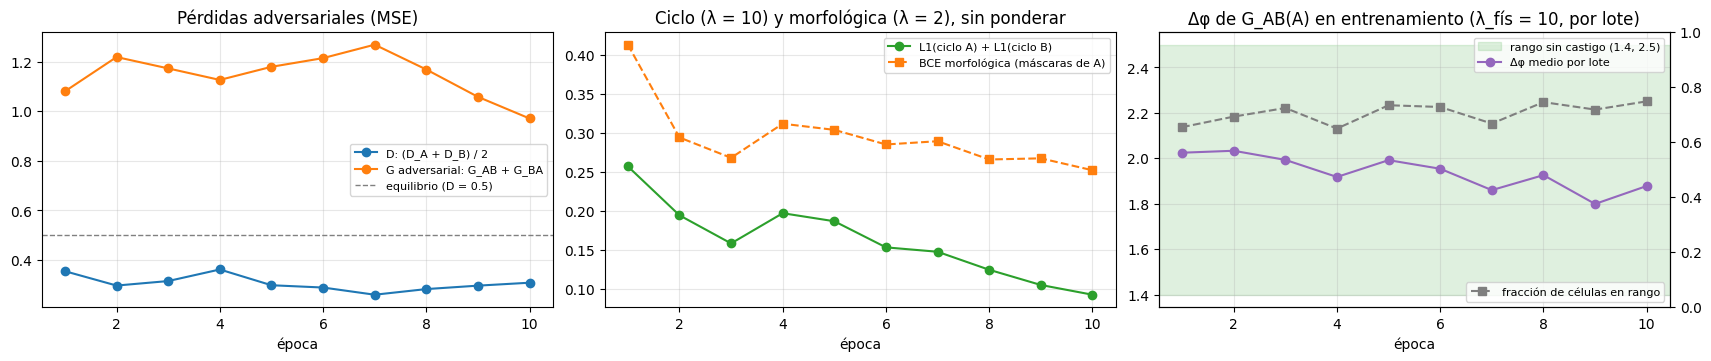

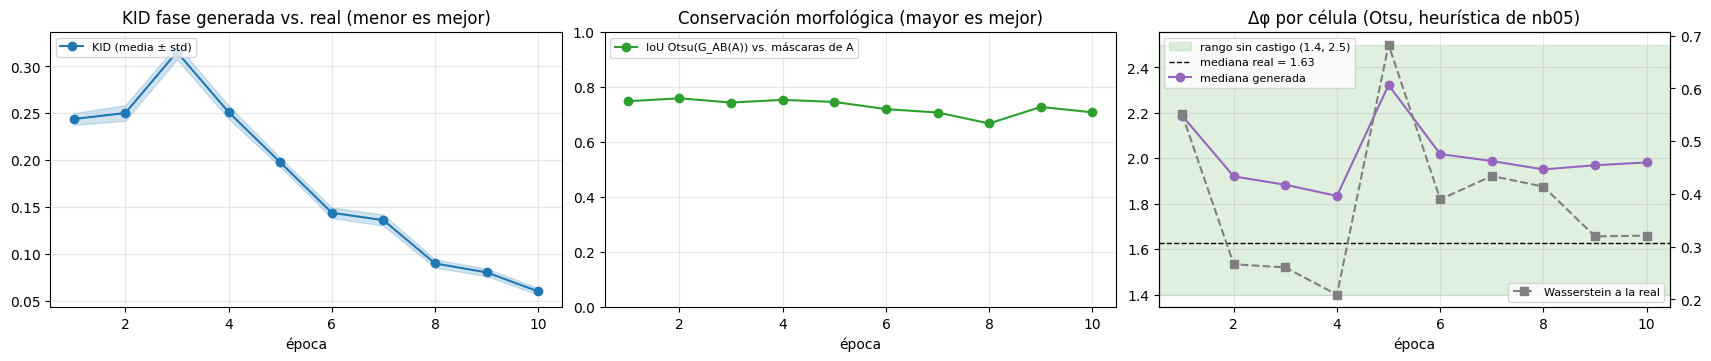

Fase real (Validation): Δφ mediana = 1.626, en rango = 60.5%, células = 1419
época      KID   ± std    IoU  Δφ med en rango     W1 células
    1   0.2439  0.0063  0.749   2.187    70.6%  0.551    2418
    2   0.2503  0.0083  0.760   1.921    89.2%  0.267    2346
    3   0.3153  0.0078  0.744   1.884    72.6%  0.261    2037
    4   0.2513  0.0070  0.754   1.835    79.7%  0.209    2458
    5   0.1978  0.0049  0.746   2.322    61.3%  0.683    2407
    6   0.1441  0.0056  0.720   2.019    85.7%  0.390    2482
    7   0.1361  0.0060  0.708   1.988    77.6%  0.434    2543
    8   0.0900  0.0043  0.668   1.951    85.4%  0.414    2442
    9   0.0805  0.0040  0.728   1.970    85.3%  0.319    2493
   10   0.0602  0.0035  0.709   1.982    86.4%  0.321    2492


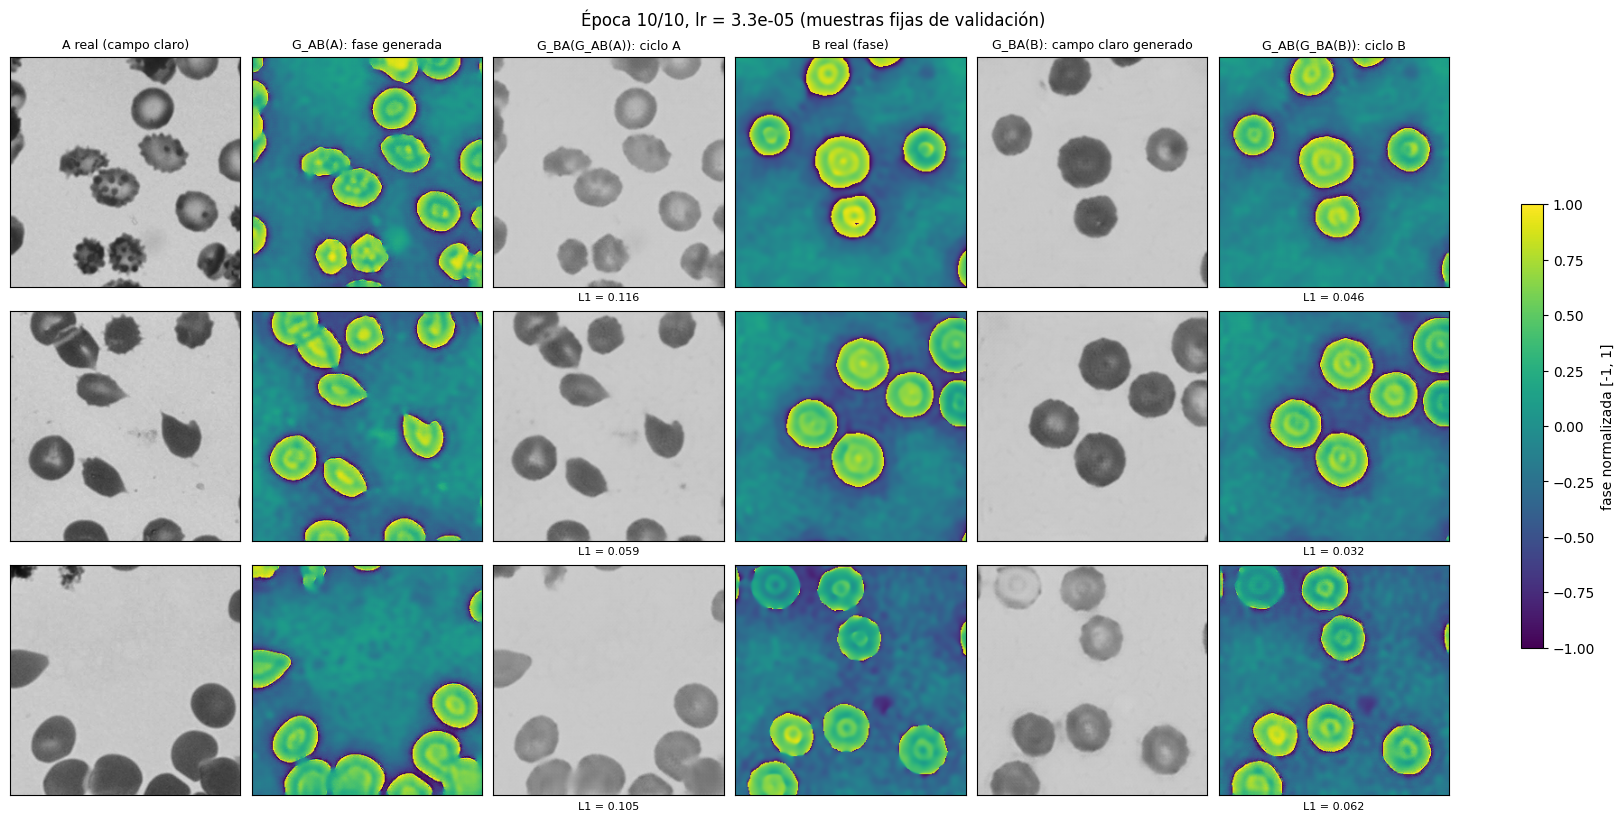

=> Saving checkpoint
=> Saving checkpoint


Epochs: 100%|██████████| 10/10 [24:08<00:00, 144.87s/it, lr=3.3e-05]

=> Saving checkpoint
=> Saving checkpoint


In [163]:
cyclegan = CycleGAN()
cyclegan.train()

## Inspección de perfiles de fase de una época

Estas dos celdas cargan los pesos guardados de una corrida y grafican los perfiles de fase de cada célula, como en nb05. El perfil de una célula es la fila de píxeles que pasa por su centroide, restringida a su máscara y con el fondo restado (la mediana de la fase fuera de las células). Δφ es el máximo menos el mínimo de ese perfil. No hace falta haber entrenado en esta sesión: basta con correr antes las celdas de setup, configuración y definiciones. Las celdas leen la corrida de `INSPECT_RUN_DIR`, que por defecto es la de la configuración actual (`RUN_DIR`).

1. **Fase generada contra fase real.** Se usan los pesos de `G_AB` de la época `INSPECT_EPOCH` (`None` = la última guardada). Arriba está `G_AB(A)` para un parche de campo claro de Validation, con sus células tomadas de las máscaras SAM de A: son las mismas células y filas que ve la pérdida física. Abajo está un parche de fase real de Validation, con sus células segmentadas con Otsu y los criterios de célula interior y la reparación de wrap de nb05, igual que en la validación. Los dos parches no son la misma escena: la comparación es entre distribuciones de perfiles.
2. **Ciclo de la fase: B → A → B.** Un parche de fase real se pasa a campo claro con `G_BA` y se vuelve a fase con `G_AB`. Los perfiles de la fase real y los de la reconstruida se miden en las mismas células y filas (las de Otsu sobre la fase real), así que se pueden superponer célula por célula. Solo se guardan los pesos de `G_BA` de la última época (`gen_ba.pth.tar`), así que esta celda usa los dos generadores del checkpoint final, sin importar `INSPECT_EPOCH`.

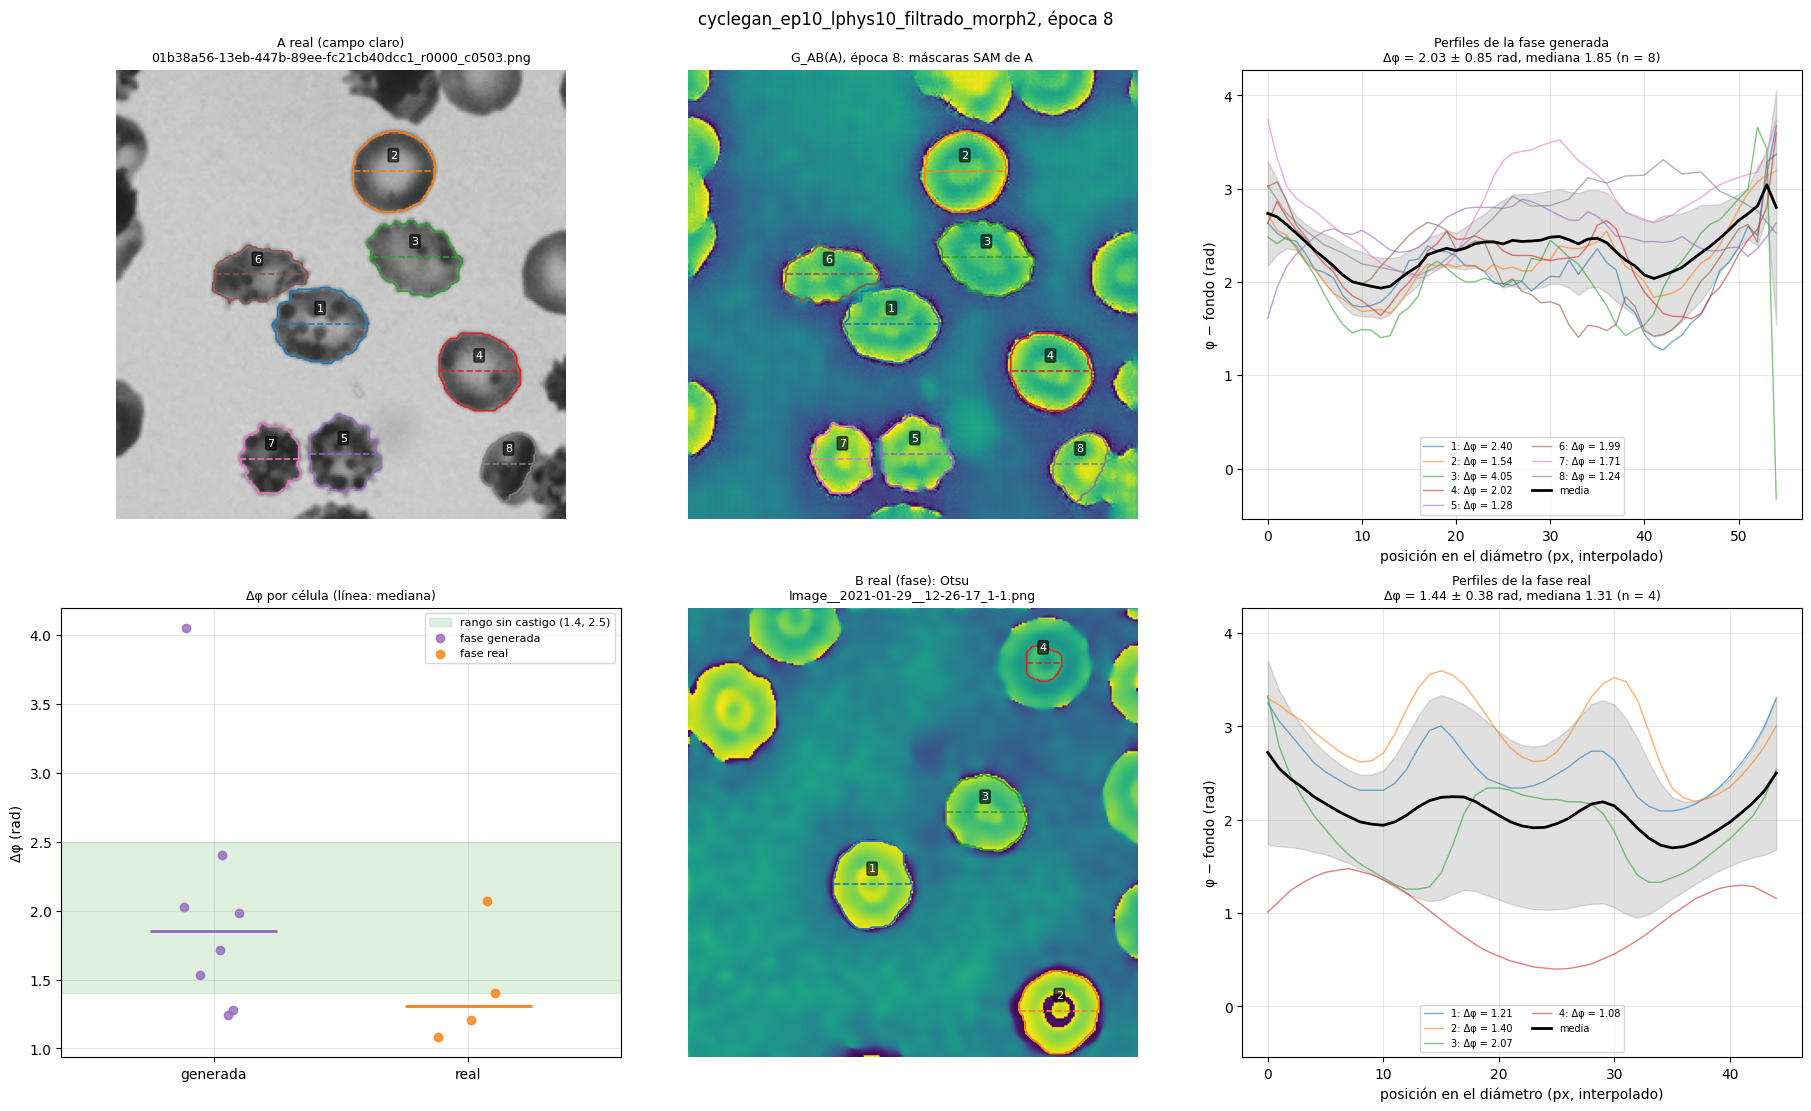

In [164]:
# Perfiles de fase de una época: fase generada G_AB(A) (arriba) y fase real (abajo), como en nb05
INSPECT_RUN_DIR = RUN_DIR  # carpeta de la corrida a inspeccionar; por defecto, la de la configuración actual
INSPECT_EPOCH = 8       #@param {type:"raw"}
A_INDEX = 0                #@param {type:"integer"}
B_INDEX = 0                #@param {type:"integer"}
N_SHOW_CELLS = 10          # células que se dibujan por imagen como máximo (las de mayor área)


def epoch_weights(run_dir, epoch=None):
    """Ruta y número de los pesos de G_AB de una época (gen_ab_por_epoca); epoch=None = la última guardada."""
    files = sorted((run_dir / 'checkpoints' / 'gen_ab_por_epoca').glob('gen_ab_epoch_*.pth'))
    if not files:
        raise FileNotFoundError(f'No hay pesos por época en {run_dir}. ¿Ya terminó al menos una época de esa corrida?')
    available = [int(f.stem.split('_')[-1]) for f in files]
    if epoch is None:
        return files[-1], available[-1]
    if epoch not in available:
        raise FileNotFoundError(f'No están los pesos de la época {epoch} en {run_dir}; hay: {available}')
    return files[available.index(epoch)], epoch


def load_generator(path):
    """Generator en modo eval desde un state_dict (pesos por época) o un checkpoint de save_checkpoint."""
    gen = Generator().to(DEVICE)
    state = torch.load(path, map_location=DEVICE)
    gen.load_state_dict(state['state_dict'] if 'state_dict' in state else state)
    return gen.eval()


def load_png(path):
    """PNG -> tensor (1, 1, H, W) en [-1, 1], como en el Dataset."""
    return TF.normalize(TF.to_tensor(np.array(Image.open(path))), (0.5,), (0.5,))[None].to(DEVICE)


def as_phase(x):
    """Tensor (1, 1, H, W) en [-1, 1] -> fase en radianes (H, W): φ = π·x, la escala de to_phase de nb05."""
    return np.pi * x[0, 0].float().cpu().numpy().astype(np.float64)


def make_cell(phi, seg, bg):
    """Perfil de nb05: fila del centroide restringida a la máscara, menos el fondo. None si tiene menos de 3 px."""
    cy = int(np.nonzero(seg)[0].mean())  # = int(m01 / m00) de cv2.moments
    xs = np.nonzero(seg[cy])[0]
    if len(xs) <= 2:
        return None
    profile = phi[cy, xs] - bg
    return dict(seg=seg, cy=cy, xs=xs, profile=profile, dphi=float(profile.max() - profile.min()),
                cx=float(np.nonzero(seg)[1].mean()), area=int(seg.sum()))


def sam_cells(phi, inst):
    """Células de las máscaras SAM que no tocan el borde (las que usa la pérdida física), sin reparar wrap."""
    bg = float(np.median(phi[inst == 0])) if (inst == 0).any() else 0.0
    cells = [make_cell(phi, inst == lab, bg) for lab in np.unique(inst[inst > 0]) if not touches_border(inst == lab)]
    return [c for c in cells if c is not None]


def otsu_cells(phi, fg=None):
    """Células interiores de Otsu con wrap reparado, como dphi_otsu (validación)."""
    fg = foreground_mask(phi) if fg is None else fg
    bg = float(np.median(phi[~fg])) if (~fg).any() else 0.0
    lab, n = ndi.label(fg)
    cells = []
    for i in range(1, n + 1):
        seg = lab == i
        if is_interior_cell(seg):
            phi_c, _ = repair_wrapped_spots(phi, seg)
            cells.append(make_cell(phi_c, seg, bg))
    return [c for c in cells if c is not None]


def largest(cells, n=N_SHOW_CELLS):
    return sorted(cells, key=lambda c: -c['area'])[:n]


CELL_COLORS = plt.cm.tab10(np.arange(10))


def draw_cells(ax, img, cells, title, **imshow_kw):
    """Imagen con el contorno de cada célula, su número y la fila del centroide (línea punteada)."""
    ax.imshow(img, **imshow_kw)
    for i, c in enumerate(cells):
        col = CELL_COLORS[i % 10]
        ax.contour(c['seg'].astype(float), levels=[0.5], colors=[col], linewidths=1.2)
        ax.plot([c['xs'].min(), c['xs'].max()], [c['cy'], c['cy']], color=col, lw=1.2, ls='--')
        ax.text(c['cx'], c['cy'] - 6, str(i + 1), color='white', fontsize=8, ha='center', va='bottom',
                bbox=dict(boxstyle='round,pad=0.15', fc='black', alpha=0.6))
    ax.set_title(title, fontsize=9)
    ax.axis('off')


def draw_profiles(ax, cells, title):
    """Perfiles individuales (interpolados al mismo largo, como annotate_image de nb05) y su media ± std."""
    if not cells:
        ax.text(0.5, 0.5, 'Sin células válidas', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(title, fontsize=9)
        return
    L = max(len(c['profile']) for c in cells)
    grid = np.linspace(0, 1, L)
    stacked = np.array([np.interp(grid, np.linspace(0, 1, len(c['profile'])), c['profile']) for c in cells])
    for i, (c, p) in enumerate(zip(cells, stacked)):
        ax.plot(np.arange(L), p, color=CELL_COLORS[i % 10], lw=1, alpha=0.6, label=f"{i + 1}: Δφ = {c['dphi']:.2f}")
    mean, std = stacked.mean(0), stacked.std(0)
    ax.plot(np.arange(L), mean, color='black', lw=2, label='media')
    ax.fill_between(np.arange(L), mean - std, mean + std, color='black', alpha=0.12)
    d = np.array([c['dphi'] for c in cells])
    ax.set_title(f'{title}\nΔφ = {d.mean():.2f} ± {d.std():.2f} rad, mediana {np.median(d):.2f} (n = {len(d)})', fontsize=9)
    ax.set_xlabel('posición en el diámetro (px, interpolado)')
    ax.set_ylabel('φ − fondo (rad)')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, ncol=2, loc='lower center')


weights, epoch = epoch_weights(INSPECT_RUN_DIR, INSPECT_EPOCH)
gen_AB_epoch = load_generator(weights)

a_names = filtered_A('Validation')  # los mismos parches A que usa la validación (con el filtro de densidad, si está activo)
b_paths = sorted((PHASE_DIR / 'Validation').glob('*.png'))
a_path = BRIGHTFIELD_DIR / 'Validation' / a_names[A_INDEX % len(a_names)]
b_path = b_paths[B_INDEX % len(b_paths)]

with torch.no_grad():
    real_A = load_png(a_path)
    phi_gen = as_phase(gen_AB_epoch(real_A))
phi_real = as_phase(load_png(b_path))
inst = np.load(MASKS_DIR / 'Validation' / f'{a_path.stem}.npz')['inst']

gen_cells, real_cells = largest(sam_cells(phi_gen, inst)), largest(otsu_cells(phi_real))
phase_kw = dict(cmap=PHASE_CMAP, vmin=-np.pi, vmax=np.pi)

fig, axes = plt.subplots(2, 3, figsize=(18, 11), constrained_layout=True)
draw_cells(axes[0, 0], real_A[0, 0].cpu().numpy(), gen_cells, f'A real (campo claro)\n{a_path.name}', cmap='gray', vmin=-1, vmax=1)
draw_cells(axes[0, 1], phi_gen, gen_cells, f'G_AB(A), época {epoch}: máscaras SAM de A', **phase_kw)
draw_profiles(axes[0, 2], gen_cells, 'Perfiles de la fase generada')
draw_cells(axes[1, 1], phi_real, real_cells, f'B real (fase): Otsu\n{b_path.name}', **phase_kw)
draw_profiles(axes[1, 2], real_cells, 'Perfiles de la fase real')
axes[1, 2].sharey(axes[0, 2])

# Δφ por célula de las dos imágenes frente al rango sin castigo
ax = axes[1, 0]
ax.axhspan(*DPHI_RANGE, color='tab:green', alpha=0.15, label=f'rango sin castigo {DPHI_RANGE}')
rng_jit = np.random.default_rng(0)
for x, cells, name, col in ((0, gen_cells, 'generada', 'tab:purple'), (1, real_cells, 'real', 'tab:orange')):
    d = [c['dphi'] for c in cells]
    ax.scatter(x + rng_jit.uniform(-0.12, 0.12, len(d)), d, color=col, alpha=0.8, label=f'fase {name}')
    if d:
        ax.hlines(np.median(d), x - 0.25, x + 0.25, color=col, lw=2)
ax.set_xticks([0, 1], ['generada', 'real'])
ax.set_xlim(-0.6, 1.6)
ax.set_ylabel('Δφ (rad)')
ax.set_title('Δφ por célula (línea: mediana)', fontsize=9)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

fig.suptitle(f'{INSPECT_RUN_DIR.name}, época {epoch}', fontsize=12)
fig.savefig(INSPECT_RUN_DIR / 'plots' / f'perfiles_epoch_{epoch:03d}_A{A_INDEX}_B{B_INDEX}.png', dpi=120, bbox_inches='tight')
plt.show()

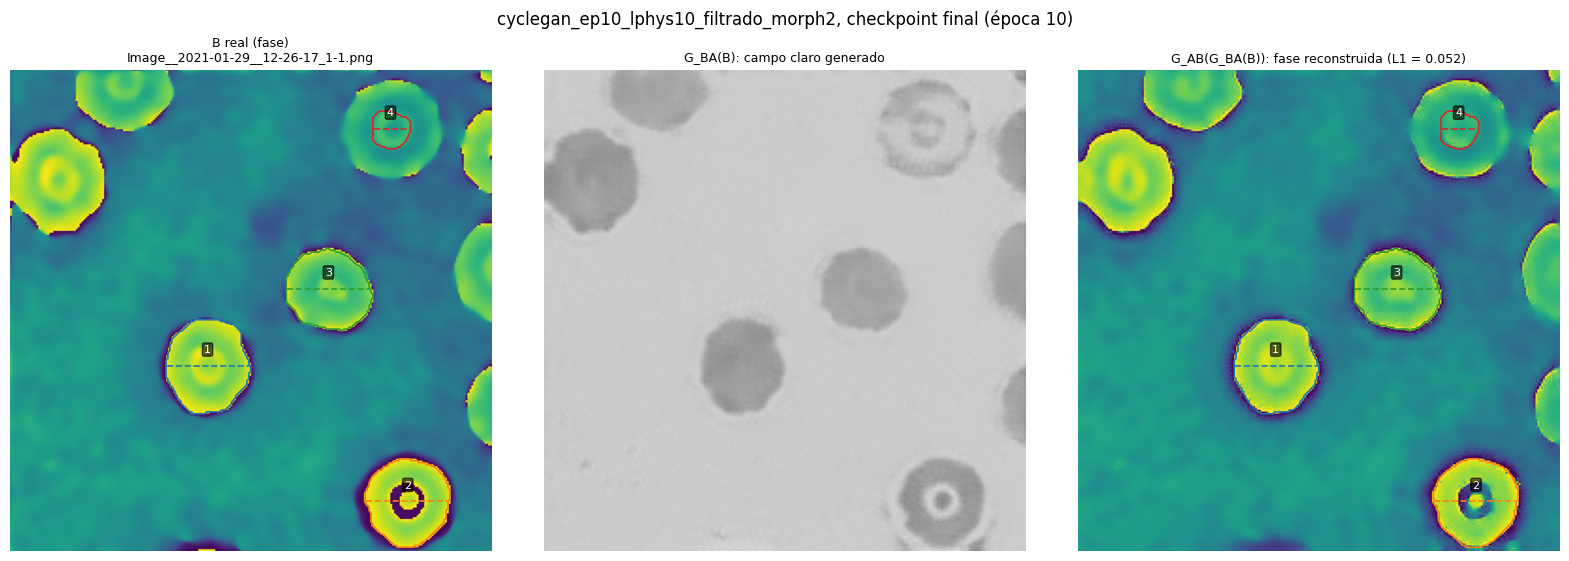

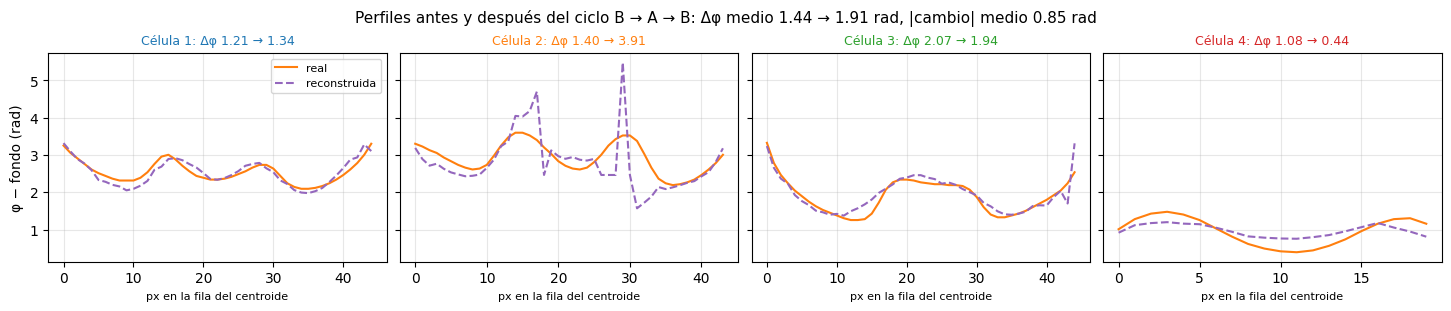

In [165]:
# Perfiles de una imagen de fase antes y después del ciclo B -> A -> B: B real contra G_AB(G_BA(B))
CYCLE_B_INDEX = 0  #@param {type:"integer"}

# Solo se guardan los pesos de G_BA de la última época, así que se usan los dos generadores del checkpoint final
ckpt_dir = INSPECT_RUN_DIR / 'checkpoints'
gen_AB_last = load_generator(ckpt_dir / 'gen_ab.pth.tar')
gen_BA_last = load_generator(ckpt_dir / 'gen_ba.pth.tar')
hist_file = ckpt_dir / 'history.json'
last_epoch = len(json.loads(hist_file.read_text())['D']) if hist_file.is_file() else '?'

b_path = b_paths[CYCLE_B_INDEX % len(b_paths)]
with torch.no_grad():
    real_B = load_png(b_path)
    fake_A = gen_BA_last(real_B)
    rec_B = gen_AB_last(fake_A)
phi_real, phi_rec = as_phase(real_B), as_phase(rec_B)

# Las mismas células y filas en las dos fases: las de Otsu sobre la fase real. El fondo de cada fase es la
# mediana fuera de esas células, y el wrap se repara en cada una por separado, como en la validación
fg = foreground_mask(phi_real)
real_cells = largest(otsu_cells(phi_real, fg))
bg_rec = float(np.median(phi_rec[~fg])) if (~fg).any() else 0.0
rec_cells = [make_cell(repair_wrapped_spots(phi_rec, c['seg'])[0], c['seg'], bg_rec) for c in real_cells]
pairs = [(r, c) for r, c in zip(real_cells, rec_cells) if c is not None]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), constrained_layout=True)
draw_cells(axes[0], phi_real, [r for r, _ in pairs], f'B real (fase)\n{b_path.name}', **phase_kw)
axes[1].imshow(fake_A[0, 0].float().cpu().numpy(), cmap='gray', vmin=-1, vmax=1)
axes[1].set_title('G_BA(B): campo claro generado', fontsize=9)
axes[1].axis('off')
l1 = (rec_B - real_B).abs().mean().item()
draw_cells(axes[2], phi_rec, [c for _, c in pairs], f'G_AB(G_BA(B)): fase reconstruida (L1 = {l1:.3f})', **phase_kw)
fig.suptitle(f'{INSPECT_RUN_DIR.name}, checkpoint final (época {last_epoch})', fontsize=12)
plt.show()

if not pairs:
    print('No hay células interiores válidas en esta imagen de fase; prueba otro CYCLE_B_INDEX.')
else:
    ncols = min(len(pairs), 5)
    nrows = int(np.ceil(len(pairs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.0 * nrows), squeeze=False, constrained_layout=True, sharey=True)
    for i, (r, c) in enumerate(pairs):
        ax = axes.flat[i]
        x = r['xs'] - r['xs'].min()
        ax.plot(x, r['profile'], color='tab:orange', lw=1.5, label='real')
        ax.plot(x, c['profile'], color='tab:purple', lw=1.5, ls='--', label='reconstruida')
        ax.set_title(f"Célula {i + 1}: Δφ {r['dphi']:.2f} → {c['dphi']:.2f}", fontsize=9, color=CELL_COLORS[i % 10])
        ax.set_xlabel('px en la fila del centroide', fontsize=8)
        ax.grid(alpha=0.3)
    for ax in axes.flat[len(pairs):]:
        ax.axis('off')
    for ax in axes[:, 0]:
        ax.set_ylabel('φ − fondo (rad)')
    axes.flat[0].legend(fontsize=8)
    d_real = np.array([r['dphi'] for r, _ in pairs])
    d_rec = np.array([c['dphi'] for _, c in pairs])
    fig.suptitle(f'Perfiles antes y después del ciclo B → A → B: Δφ medio {d_real.mean():.2f} → {d_rec.mean():.2f} rad, '
                 f'|cambio| medio {np.abs(d_rec - d_real).mean():.2f} rad', fontsize=11)
    fig.savefig(INSPECT_RUN_DIR / 'plots' / f'ciclo_B_perfiles_B{CYCLE_B_INDEX}.png', dpi=120, bbox_inches='tight')
    plt.show()

## Decisiones y limitaciones de la variante física

Decisiones tomadas el 2026-11-11 (issue [#13](https://github.com/Jacogz/DL-QPI/issues/13)).

### Decisiones

1. **Qué mide Δφ.** Δφ es el $\max - \min$ del perfil de la célula, tal como se calcula y se reporta en nb05 (`extract_phase_profile_bg_global`). No es la altura sobre el fondo (`profile.max()`): el fondo se resta de los dos extremos y se cancela. La profundidad bicóncava (anillo contra centro) quedó fuera del alcance.
2. **Rango sin castigo: [1.4, 2.5].** Es una decisión arbitraria del equipo. La justificación es que el dataset de fase solo contiene eritrocitos sanos, cuyos perfiles de fase completos deben estar en ese rango. Como referencia, en la muestra de nb05 (28 células interiores de 8 imágenes) los cuartiles de Δφ son 1.48 y 2.32 y la mediana es 1.90. El rango coincide aproximadamente con ese rango intercuartil, pero la muestra es pequeña y no se usó para ajustar el rango.
3. **Castigo por lote y suavizado (diseño inicial, ver la decisión 10).** Se castiga el Δφ medio de todas las células del lote con una bisagra cuadrática: vale cero dentro del rango, así que los valores normales no se castigan, y crece al cuadrado afuera, así que los valores improbables se castigan fuerte. Se descartaron un valor objetivo escalar y un rango discreto por célula porque podrían llevar al modelo a distorsionar las fases para cumplirlos. Al castigar la media del lote, una célula individual puede quedar fuera del rango, y eso conserva la diversidad de células del dataset.
4. **Solo en A → B y con las máscaras de A.** El término se aplica a `G_AB(A)` con las máscaras de campo claro. En B real no hay máscaras, y en la dirección B → A el término no aporta nada que la consistencia de ciclo no aporte ya.
5. **Sin término morfológico.** Con la sola consistencia de ciclo, `fake_B` ya conserva bien la morfología de A, así que no se agrega un término de máscaras sobre la fase generada. Se revirtió en la decisión 12.
6. **Células excluidas.** Como en nb05, se excluyen las células que tocan el borde del parche (margen de 2 px), porque su perfil está cortado. También se excluyen las células cuya fila central tiene menos de 3 px, que nb05 tampoco mide.
7. **Sin reparación de wrap.** `repair_wrapped_spots` de nb05 corrige fase envuelta en las imágenes reales. Es un paso aparte de la función del perfil, y la salida del generador (tanh) es continua y no se envuelve, así que no se aplica.
8. **Validación durante el entrenamiento.** Se calcula al final de cada época (`CycleGAN.validate`), para ver las curvas en vivo. La alternativa era calcularla después del entrenamiento sobre los checkpoints por época de `G_AB`. Esta opción suma unos minutos a cada época, pero no requiere un paso aparte.
9. **Grid.** Son 3 corridas de 10 épocas, cada una en su propia carpeta `runs/cyclegan_ep10_lphys<λ>[_celula]`: $\lambda_{fis} = 0$, $\lambda_{fis} = 1$ por lote y $\lambda_{fis} = 10$ por célula. El plan inicial era $\lambda_{fis} \in \{0, 1, 10\}$, todas por lote (ver la decisión 10). Con el filtro de densidad (decisión 11) se repiten en carpetas `..._filtrado`: primero $\lambda_{fis} = 0$ y $\lambda_{fis} = 10$ por célula, y $\lambda_{fis} = 1$ por lote si hay tiempo. La corrida con $\lambda_{fis} = 0$ es el baseline con el mismo código y el mismo cronograma de LR. Por eso la comparación no usa el baseline anterior de 20 épocas (`runs/cyclegan`), cuyo LR empieza a decaer en la época 10.
10. **Cambio a castigo por célula después de la primera corrida (2026-11-11).** La corrida con $\lambda_{fis} = 1$ por lote mostró que el término queda inerte. El Δφ medio de los lotes estuvo entre 1.64 y 1.90 en todas las épocas, dentro del rango, así que la bisagra casi no aportó: $\mathcal{L}_{\Delta\phi}$ valió entre 0.005 y 0.024, frente a entre 0.8 y 1.9 del término de ciclo ponderado y ~1.1 del adversarial. Con $\lambda_{fis} = 10$ por lote el término seguiría siendo pequeño. En cambio, solo entre el 18 % y el 48 % de las células estaban dentro del rango. La media del lote ya cumple la restricción sin el término, pero las células una por una no la cumplen. Por eso la tercera corrida usa el castigo por célula (`PHYS_MODE = "celula"`) con $\lambda_{fis} = 10$, a cambio del riesgo de comprimir la distribución de Δφ descrito al final.
11. **Filtro de densidad de células en campo claro (2026-11-11).** Las muestras de la corrida $\lambda_{fis} = 1$ y las del baseline de 20 épocas borran o funden las células que se tocan (ver "Distinta densidad de células entre dominios" en las limitaciones). Desde entonces se entrena y se valida solo con los parches A con hasta `MAX_CELLS_A` = 8 células y sin células en contacto (`MAX_CONTACT_FRAC` = 0, a 2 px). Ambas cantidades salen de las máscaras SAM. Las corridas con filtro van en carpetas `..._filtrado` y no se comparan con las de sin filtro, porque el conjunto de validación de A también cambia.

12. **Pérdida morfológica (2026-11-12).** La decisión 5 resultó falsa: en la corrida filtrada de 20 épocas, `G_AB` dibujó la fase con la polaridad invertida (células oscuras y fondo claro) hasta la época 17, y en las dos corridas con la entrada de campo claro negada la polaridad salió invertida en todas las épocas, con las células de `fake_B` donde A tiene fondo. El ciclo A se reconstruía igual (L1 ≈ 0.04): la consistencia de ciclo restringe el viaje de ida y vuelta, no la imagen intermedia, y ningún término ligaba la posición de las células de A con la de B. Se agrega

$$\mathcal{L}_{morf} = \mathrm{BCE}\left(\sigma\!\left(\frac{G_{AB}(A) - t}{\tau}\right),\ M_A\right)$$

donde $M_A$ es la unión de las máscaras SAM de A (incluidas las del borde), $t$ es la mediana del umbral de Otsu de la fase real de Training (`phase_fg_threshold`, el mismo procedimiento que `foreground_mask` de la validación) y $\tau = 0.1$. El peso es $\lambda_{morf} = 2$, del orden de la pérdida adversarial y del ciclo ponderado. Fija la polaridad y la posición a la vez. La alternativa, la pérdida de identidad del CycleGAN original, solo empuja a `G_AB` a cambiar poco las fases reales y no restringe lo que hace con el campo claro. **Consecuencia para la evaluación:** el IoU de validación (Otsu de la fase generada contra las máscaras de A) mide casi lo mismo que se optimiza, así que deja de ser una métrica independiente; en las corridas con este término las métricas independientes son el KID, la distribución de Δφ (mediana, fracción en rango, W1) y los perfiles. Las corridas van en carpetas `..._morph2`.

### Limitaciones

- **Escala de la fase no normalizada entre imágenes.** La conversión $\phi = g/255 \cdot 2\pi - \pi$ es fija, pero los PNG de origen están normalizados min-max por recorte (nb04, sección 0.5): el 100 % de los recortes tiene mínimo 0 y máximo 255 exactos. Por eso Δφ está en unidades relativas a cada recorte, no en radianes físicos comparables con una medición DHM. El modelo imita la distribución del dataset tal como está, incluido el estiramiento si existe. Un Δφ "plausible" significa plausible respecto a este dataset.
- **El gradiente de max − min es disperso.** Por cada célula, el gradiente llega solo al píxel del máximo y al del mínimo de su fila central. El generador podría cumplir el rango moviendo esos dos píxeles (por ejemplo, con un pico aislado) en vez de cambiar el perfil completo. Hay que revisar las muestras de cada época buscando ese artefacto. Una versión suave (log-sum-exp o percentiles sobre toda la máscara) lo evitaría, pero dejaría de ser la misma medida que se reporta.
- **Alineación máscara–fase.** Las máscaras se segmentan sobre el campo claro y se aplican a la fase generada. Esto supone que `G_AB` no desplaza las células. Si lo hiciera, Δφ se mediría sobre la región equivocada. Sin la pérdida morfológica, sí las desplazaba (decisión 12).
- **Células solapadas.** En el mapa de instancias, las células pequeñas se pintan encima de las grandes, así que la fila de una célula parcialmente tapada pierde los píxeles de la otra. En nb05 cada máscara de SAM era completa.
- **El Δφ de entrenamiento no es una validación.** La curva de Δφ de `losses.png` se calcula sobre los batches de entrenamiento con las máscaras de A, y es la misma cantidad que se optimiza. La validación es aparte (`validation.png`).
- **Segmentación de la validación.** Otsu une las células que se tocan. Esas uniones no se separan: los criterios de célula interior de nb05 (forma y `fill_ratio`) las descartan. Por eso el Δφ de validación representa sobre todo células aisladas, en la fase generada y en la real por igual. El IoU compara Otsu sobre la fase contra SAM sobre el campo claro, así que el halo de la fase baja su valor absoluto: sirve para comparar corridas y épocas, no como valor absoluto.
- **Distinta densidad de células entre dominios (limitación principal).** Los parches de fase tienen pocas células, redondas y separadas. Los de campo claro tienen muchas, que se tocan y se enciman. El discriminador de fase nunca ve células pegadas, así que `G_AB` aprende a borrarlas o fundirlas en los racimos y guarda la información de forma invisible para reconstruir A en el ciclo ("esteganografía" de CycleGAN): el L1 del ciclo A sigue bajo donde la célula no se ve en `fake_B`. Las células aisladas sí salen con un perfil plausible. Esto ya ocurre en el baseline de 20 épocas (`runs/cyclegan`), así que no lo causa el término físico, y ningún peso de ese término lo corrige. Se mitiga con el filtro de densidad (decisión 11). El filtro reduce y sesga el conjunto de campo claro hacia frotis poco densos, así que el modelo no queda evaluado en parches con racimos.
- **KID con una Inception de ImageNet.** Sus features no fueron entrenadas con imágenes de fase. El KID sirve para comparar corridas entre sí, no como medida absoluta de realismo.

### Castigo por célula (`PHYS_MODE = "celula"`)

Era la implementación alternativa y se implementó después de la primera corrida (decisión 10). En lugar de castigar la media del lote, se castiga cada célula y se promedia:

$$\mathcal{L}_{\Delta\phi}^{\text{célula}} = \frac{1}{N}\sum_{i=1}^{N} \left[\mathrm{ReLU}(1.4 - \Delta\phi_i)^2 + \mathrm{ReLU}(\Delta\phi_i - 2.5)^2\right]$$

En `phys_loss` el cambio es aplicar la bisagra a `dphi` antes de promediar con `valid`. Así cada célula tiene su propia señal de gradiente y ninguna célula atípica queda escondida en la media. A cambio, empuja todas las células hacia el rango y puede comprimir la distribución de Δφ, perdiendo las colas que representan la diversidad de eritrocitos sanos. Por eso al principio se prefirió el castigo por lote. Para ver si esa compresión ocurre, hay que comparar en la validación la fracción en rango y la distancia de Wasserstein contra la fase real: una fracción en rango muy por encima de la real (~60 %) indica que se comprimió.

NOTAS
cyclegan_ep10_lphys1_filtrado ->